# Práctica 3. Black-Litterman y Hierarchical Risk Parity

**Asignatura:** Quant Portfolio Management  
**Máster:** Finanzas Cuantitativas y Métodos Computacionales

## Objetivo

Esta práctica estudia dos metodologías de construcción de carteras:

1. **Black-Litterman**, que combina rentabilidades implícitas de equilibrio con opiniones sobre los activos.
2. **Hierarchical Risk Parity (HRP)**, que utiliza técnicas de clustering jerárquico para construir carteras sin invertir directamente una matriz de covarianzas.

Ambas metodologías se evalúan mediante un backtesting walk-forward y se comparan con carteras equiponderadas y optimizadas mediante Markowitz.

## 1. Metodología y reproducibilidad

El análisis se desarrolla mediante una arquitectura modular.

Las funciones matemáticas, los optimizadores y el motor de backtesting se encuentran implementados en el paquete `quantmgmt` y cuentan con pruebas automatizadas independientes.

Este notebook utiliza dichas funciones para reproducir los experimentos, visualizar los resultados e interpretar sus implicaciones financieras.

Se utiliza Python, NumPy, pandas, SciPy y Matplotlib.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "quantmgmt").is_dir():
    raise RuntimeError(
        "Ejecuta el notebook desde la raíz del repositorio "
        "o desde su carpeta notebooks."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Proyecto:", PROJECT_ROOT)

Proyecto: G:\Mi unidad\MAIN\MÁSTER QUANT HESPERIDES\Tercer semestre\Quant portfolio management\Prácticas\quant-management


## 2. Universo de inversión

Se seleccionan 12 ETF negociados en USD que representan distintas clases de activos y exposiciones geográficas.

| ETF | Clase de activo | Exposición |
|---|---|---|
| SPY | Renta variable | Estados Unidos, S&P 500 |
| IWM | Renta variable | Estados Unidos, pequeñas compañías |
| EFA | Renta variable | Mercados desarrollados fuera de Norteamérica |
| EEM | Renta variable | Mercados emergentes |
| TLT | Renta fija | Bonos del Tesoro estadounidense de larga duración |
| IEF | Renta fija | Bonos del Tesoro estadounidense de duración intermedia |
| LQD | Renta fija | Bonos corporativos investment grade |
| HYG | Renta fija | Bonos corporativos high yield |
| GLD | Materias primas | Oro |
| DBC | Materias primas | Cesta diversificada de futuros |
| VNQ | Inmobiliario | REIT estadounidenses |
| TIP | Renta fija | Bonos del Tesoro ligados a la inflación |

### Justificación del universo

El universo permite estudiar distintas fuentes de rentabilidad y riesgo, incluyendo renta variable, duración, crédito, inflación, materias primas e inmobiliario cotizado.

La selección resulta adecuada para comparar enfoques basados en covarianzas, equilibrio de mercado y agrupaciones jerárquicas.

### Mandato de inversión

Se considera una cartera estratégica multiactivo, denominada en USD, con las siguientes restricciones:

- Posiciones largas exclusivamente.
- Sin apalancamiento.
- Inversión completamente asignada.
- Rebalanceo trimestral.
- Ventana de estimación de 36 meses.
- Horizonte de evaluación plurianual.

El objetivo es comparar metodologías de construcción de carteras, no optimizar retrospectivamente una estrategia de trading.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from quantmgmt.data.loader import load_prices

from quantmgmt.optimizers.mean_variance import (
    estimate_inputs,
    min_variance,
    max_sharpe,
)

from quantmgmt.optimizers.black_litterman import (
    implied_equilibrium_returns,
    posterior_returns,
    build_omega,
)

from quantmgmt.optimizers.hrp import (
    hrp_weights,
    inverse_volatility_weights,
    risk_contribution,
)

from quantmgmt.backtesting.views import (
    momentum_relative_view,
    three_relative_views,
)

from quantmgmt.backtesting.comparison import (
    default_market_weights,
    run_strategy_comparison,
)

from quantmgmt.backtesting.metrics import evaluate_backtest

plt.rcParams["figure.figsize"] = (12, 6)
pd.options.display.float_format = "{:.4f}".format

print("Importaciones correctas")

Importaciones correctas


## 3. Datos históricos

Se utilizan precios ajustados de los 12 ETF obtenidos mediante Yahoo Finance.

El período de análisis comprende desde enero de 2012 hasta el 2 de noviembre de 2026.

Los precios ajustados permiten aproximar las rentabilidades totales, incorporando ajustes por distribuciones y operaciones corporativas.

Se calculan rentabilidades simples diarias:

$$
r_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1
$$

El histórico inicial se utiliza para estimar los parámetros de las estrategias.

La evaluación fuera de muestra comienza después de disponer de una ventana histórica de 36 meses y utiliza rebalanceos trimestrales.

La fecha final de descarga se fija expresamente para facilitar la reproducibilidad del experimento.

In [3]:
TICKERS = [
    "SPY", "IWM", "EFA", "EEM",
    "TLT", "IEF", "LQD", "HYG",
    "GLD", "DBC", "VNQ", "TIP",
]

START_DATE = "2012-01-01"
END_DATE = "2026-11-03"

prices = load_prices(
    tickers=TICKERS,
    start=START_DATE,
    end=END_DATE,
)

prices = prices.reindex(columns=TICKERS).sort_index()

print("Observaciones:", len(prices))
print("Primera fecha:", prices.index.min())
print("Última fecha:", prices.index.max())

display(prices.head())

Observaciones: 3730
Primera fecha: 2012-01-03 00:00:00
Última fecha: 2026-11-02 00:00:00


Ticker,SPY,IWM,EFA,EEM,TLT,IEF,LQD,HYG,GLD,DBC,VNQ,TIP
Date,,,,,,,,,,,,
2012-01-03,98.8116,61.5066,32.8643,28.6107,78.6603,75.5922,67.1149,39.9154,155.9200,23.3679,32.6946,80.3558
2012-01-04,98.9666,61.1702,32.6705,28.4497,77.7251,75.3544,67.1680,39.8487,156.7100,23.5454,32.1357,80.4316
2012-01-05,99.2301,61.5148,32.1861,28.3253,77.5868,75.3688,66.8787,39.6752,157.7800,23.2242,32.4375,80.5832
2012-01-06,98.9744,61.3589,31.7468,27.9668,78.1993,75.6642,67.1385,39.5506,157.2000,23.3256,32.3313,80.8518
2012-01-09,99.2146,61.6706,31.8695,28.2595,78.0610,75.6787,67.0381,39.6040,156.5000,23.3510,32.2195,80.9344


In [4]:
# Data quality checks
assert prices.columns.is_unique
assert prices.index.is_unique
assert prices.index.is_monotonic_increasing

missing = prices.isna().sum()

print("Valores ausentes por ETF:")
display(missing.to_frame("missing_values"))

assert missing.sum() == 0, "Existen precios ausentes"

assert np.isfinite(prices.to_numpy()).all()
assert (prices > 0).all().all()

# Daily simple returns
returns = prices.pct_change(fill_method=None).dropna()

assert np.isfinite(returns.to_numpy()).all()
assert (returns >= -1).all().all()

print("Dimensiones de retornos:", returns.shape)

display(returns.head())

Valores ausentes por ETF:


,missing_values
Ticker,
SPY,0
IWM,0
EFA,0
EEM,0
TLT,0
IEF,0
LQD,0
HYG,0
GLD,0


Dimensiones de retornos: (3729, 12)


Ticker,SPY,IWM,EFA,EEM,TLT,IEF,LQD,HYG,GLD,DBC,VNQ,TIP
Date,,,,,,,,,,,,
2012-01-04,0.0016,-0.0055,-0.0059,-0.0056,-0.0119,-0.0031,0.0008,-0.0017,0.0051,0.0076,-0.0171,0.0009
2012-01-05,0.0027,0.0056,-0.0148,-0.0044,-0.0018,0.0002,-0.0043,-0.0044,0.0068,-0.0136,0.0094,0.0019
2012-01-06,-0.0026,-0.0025,-0.0136,-0.0127,0.0079,0.0039,0.0039,-0.0031,-0.0037,0.0044,-0.0033,0.0033
2012-01-09,0.0024,0.0051,0.0039,0.0105,-0.0018,0.0002,-0.0015,0.0013,-0.0045,0.0011,-0.0035,0.0010
2012-01-10,0.0087,0.0146,0.0152,0.0218,-0.0017,-0.0020,0.0028,0.0035,0.0137,0.0072,0.0111,-0.0031


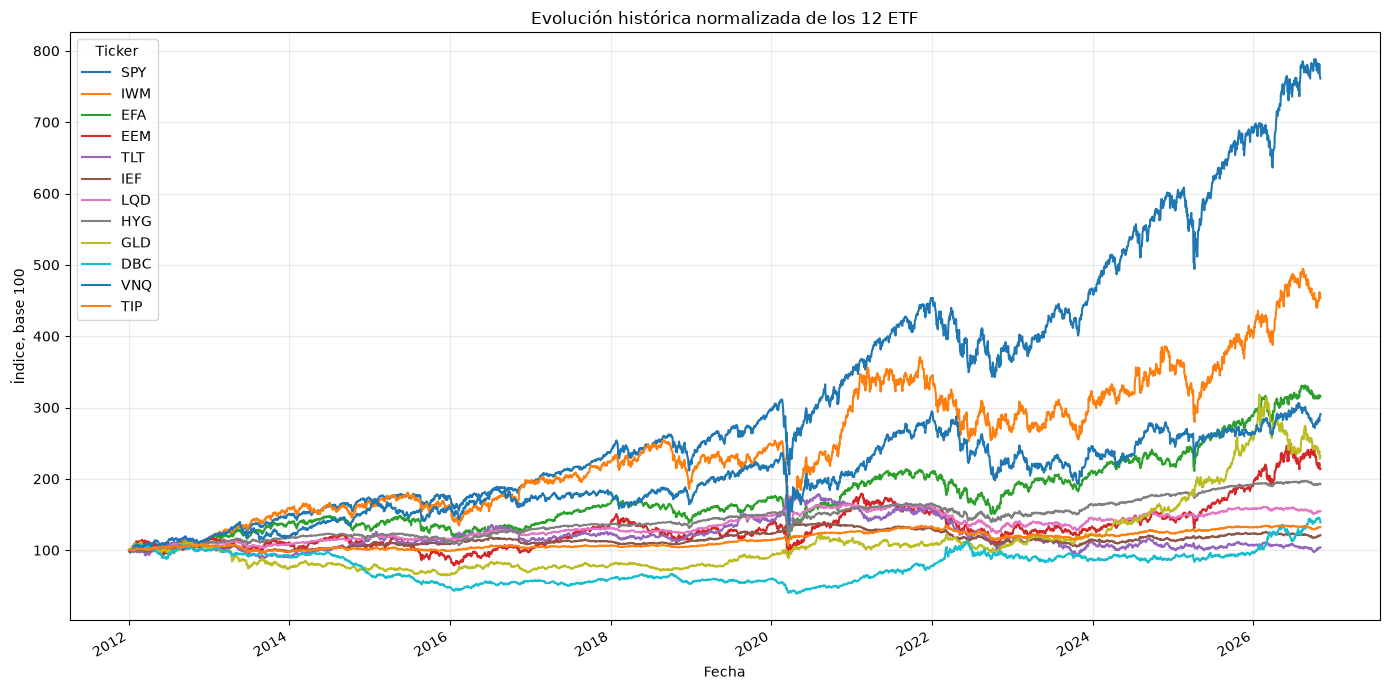

In [5]:
normalized_prices = prices.div(prices.iloc[0]).mul(100)

ax = normalized_prices.plot(
    figsize=(14, 7),
    linewidth=1.5,
)

ax.set_title("Evolución histórica normalizada de los 12 ETF")
ax.set_ylabel("Índice, base 100")
ax.set_xlabel("Fecha")

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 4. Metodología de evaluación fuera de muestra

Para evitar que las estrategias utilicen información futura, se aplica un procedimiento walk-forward.

En cada fecha de rebalanceo:

1. Se seleccionan los retornos correspondientes a los 36 meses anteriores, incluyendo la fecha de decisión.
2. Se estiman los parámetros necesarios para cada estrategia.
3. Se calculan los pesos objetivo.
4. Se ejecuta el rebalanceo al cierre de la fecha de decisión.
5. Los nuevos pesos generan rentabilidad a partir de la siguiente sesión.

El procedimiento se repite trimestralmente.

Todas las estrategias utilizan:

- El mismo universo de inversión.
- Las mismas observaciones históricas.
- Las mismas fechas de rebalanceo.
- El mismo motor de simulación.
- El mismo capital inicial de 100.000 USD.

Se consideran cinco carteras:

1. Equal Weight.
2. Minimum Variance.
3. Maximum Sharpe.
4. Black-Litterman.
5. Hierarchical Risk Parity.

El experimento principal utiliza inicialmente costes de transacción nulos y un tipo libre de riesgo anual del 0 %.

Posteriormente se estudia la sensibilidad a los costes de transacción.

La evaluación fuera de muestra se refiere a los parámetros y pesos calculados en cada rebalanceo. No elimina el posible sesgo retrospectivo introducido al seleccionar las hipótesis estratégicas de Black-Litterman.

## 5. Modelo Black-Litterman

El modelo Black-Litterman combina dos fuentes de información:

1. **Rentabilidades implícitas de equilibrio**, obtenidas a partir de una cartera de referencia.
2. **Opiniones del inversor**, que expresan expectativas absolutas o relativas sobre determinados activos.

El objetivo es construir un vector de rentabilidades esperadas que incorpore ambas fuentes de información de manera consistente.

### 5.1. Rentabilidades implícitas de equilibrio

Se calculan mediante:

$$
\Pi = \delta \Sigma w_{mkt}
$$

Donde:

- $\Pi$ es el vector de rentabilidades implícitas de equilibrio.
- $\delta$ representa el coeficiente de aversión al riesgo.
- $\Sigma$ es la matriz de covarianzas anualizada.
- $w_{mkt}$ representa los pesos de la cartera de referencia.

El modelo interpreta estas rentabilidades como las primas de riesgo compatibles con la cartera de equilibrio y la aversión al riesgo seleccionada.

### Cartera de referencia

En esta práctica utilizamos una cartera estratégica hipotética.

No representa las ponderaciones reales por capitalización bursátil del mercado.

Esta elección permite construir una referencia diversificada para los 12 ETF, aunque introduce una hipótesis adicional en el modelo.

In [6]:
# Strategic benchmark used by Black-Litterman

market_weights = default_market_weights()

market_weights = market_weights.reindex(
    returns.columns
)

assert market_weights.notna().all()
assert np.isclose(market_weights.sum(), 1.0)

benchmark_table = pd.DataFrame({
    "ETF": market_weights.index,
    "Weight": market_weights.values,
})

display(benchmark_table)

print(
    "Total benchmark weight:",
    market_weights.sum(),
)

,ETF,Weight
0,SPY,0.2200
1,IWM,0.0600
2,EFA,0.1200
3,EEM,0.0800
4,TLT,0.1000
5,IEF,0.1000
6,LQD,0.0700
7,HYG,0.0400
8,GLD,0.0800
9,DBC,0.0400


Total benchmark weight: 1.0


### 5.2. Coeficiente de aversión al riesgo

El parámetro $\delta$ determina la relación entre la prima de riesgo esperada y la varianza de la cartera de referencia.

Una estimación habitual es:

$$
\delta =
\frac{E[R_m]-R_f}{\sigma_m^2}
$$

Donde:

- $E[R_m]$ representa la rentabilidad anual esperada de la cartera de referencia.
- $R_f$ es la rentabilidad anual libre de riesgo.
- $\sigma_m^2$ es la varianza anual de la cartera de referencia.

En esta práctica utilizamos inicialmente:

$$
\delta = 2.5
$$

Se trata de una hipótesis del escenario base, no de una estimación estructural conocida del mercado.

Posteriormente analizamos valores alternativos de 1.5 y 4.0 para estudiar la sensibilidad del modelo.

Esta elección evita calibrar el parámetro exclusivamente para maximizar los resultados históricos del backtesting.

In [7]:
from quantmgmt.backtesting.engine import quarterly_rebalance_dates

LOOKBACK_MONTHS = 36
RISK_FREE_RATE = 0.0
RISK_AVERSION = 2.5
TAU = 0.05

rebalance_dates = quarterly_rebalance_dates(
    returns.index,
    lookback_months=LOOKBACK_MONTHS,
)

first_rebalance = rebalance_dates[0]

first_window_start = (
    first_rebalance
    - pd.DateOffset(months=LOOKBACK_MONTHS)
)

first_window = returns.loc[
    (returns.index > first_window_start)
    & (returns.index <= first_rebalance)
]

# Returns of the fixed strategic benchmark,
# using its weights for this estimation.
benchmark_returns = (
    first_window @ market_weights
)

benchmark_mean_annual = (
    benchmark_returns.mean() * 252
)

benchmark_variance_annual = (
    benchmark_returns.var(ddof=1) * 252
)

estimated_delta = (
    benchmark_mean_annual - RISK_FREE_RATE
) / benchmark_variance_annual

print("First rebalance:", first_rebalance.date())
print("Training observations:", len(first_window))
print("Annual benchmark return:", round(benchmark_mean_annual, 4))
print("Annual benchmark variance:", round(benchmark_variance_annual, 4))
print("Illustrative estimated delta:", round(estimated_delta, 4))
print("Selected baseline delta:", RISK_AVERSION)

First rebalance: 2015-03-31
Training observations: 753
Annual benchmark return: 0.0663
Annual benchmark variance: 0.0053
Illustrative estimated delta: 12.5927
Selected baseline delta: 2.5


In [8]:
# Annualized inputs from the first historical window

historical_mu, historical_cov = estimate_inputs(
    first_window,
    periods_per_year=252,
)

pi = implied_equilibrium_returns(
    covariance_matrix=historical_cov,
    market_weights=market_weights,
    risk_aversion=RISK_AVERSION,
)

equilibrium_table = pd.DataFrame({
    "Historical mean": historical_mu,
    "Equilibrium return": pi,
    "Difference": pi - historical_mu,
})

display(
    equilibrium_table
    .sort_values(
        "Equilibrium return",
        ascending=False,
    )
)

,Historical mean,Equilibrium return,Difference
Ticker,,,
EEM,0.0142,0.0272,0.0130
EFA,0.0953,0.0226,-0.0727
IWM,0.1643,0.0219,-0.1423
VNQ,0.1421,0.0183,-0.1238
SPY,0.1558,0.0182,-0.1377
GLD,-0.1039,0.0131,0.1170
DBC,-0.1665,0.0121,0.1786
HYG,0.0598,0.0077,-0.0521
LQD,0.0541,0.0033,-0.0508


### 5.3. Construcción de opiniones

Black-Litterman representa las opiniones mediante:

$$
P\mu = Q + \varepsilon
$$

Donde:

- $P$ es la matriz de exposición de las opiniones a los activos.
- $\mu$ es el vector de rentabilidades esperadas.
- $Q$ contiene las rentabilidades expresadas por las opiniones.
- $\varepsilon$ representa el error de dichas opiniones.

La incertidumbre se representa mediante la matriz $\Omega$.

#### Opiniones seleccionadas

Se utilizan tres opiniones relativas:

**V1. Momentum relativo**

El ETF con mayor rentabilidad acumulada durante los últimos 12 meses superará al de menor rentabilidad acumulada en 3 puntos porcentuales anuales.

Confianza: 60 %.

**V2. Oro frente a materias primas**

GLD superará a DBC en 1 punto porcentual anual.

Confianza: 55 %.

**V3. Renta variable estadounidense frente a desarrollada internacional**

SPY superará a EFA en 1,5 puntos porcentuales anuales.

Confianza: 55 %.

La primera opinión es dinámica y se construye exclusivamente con información histórica disponible en cada rebalanceo.

Las otras dos son hipótesis estratégicas fijas definidas para este experimento.

Estas hipótesis no constituyen predicciones demostradas. Además, su selección se realizó con conocimiento del histórico, lo que limita la interpretación genuinamente prospectiva de los resultados.

In [9]:
P, Q, confidences = three_relative_views(
    historical_returns=first_window,
    rebalance_date=first_rebalance,
    momentum_months=12,
    expected_spread=0.03,
    confidence=0.60,
    include_gld_view=True,
    include_spy_view=True,
)

print("View matrix P:")
display(P)

print("Expected view returns Q:")
display(Q.to_frame())

print("View confidences:")
display(confidences.to_frame())

View matrix P:


Ticker,SPY,IWM,EFA,EEM,TLT,IEF,LQD,HYG,GLD,DBC,VNQ,TIP
momentum_relative,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-1.0000,1.0000,0.0000
GLD_outperforms_DBC,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,-1.0000,0.0000,0.0000
SPY_outperforms_EFA,1.0000,0.0000,-1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Expected view returns Q:


,expected_spread
momentum_relative,0.0300
GLD_outperforms_DBC,0.0100
SPY_outperforms_EFA,0.0150


View confidences:


,confidence
momentum_relative,0.6000
GLD_outperforms_DBC,0.5500
SPY_outperforms_EFA,0.5500


### 5.4. Incertidumbre de las opiniones

La matriz $\Omega$ representa la incertidumbre de las opiniones.

En esta implementación se utiliza una matriz diagonal, por lo que se supone que los errores de las opiniones son independientes.

Para cada opinión, la incertidumbre se construye a partir de su exposición a la matriz de covarianzas, el parámetro $\tau$ y el nivel de confianza.

Una confianza mayor implica una menor incertidumbre y, por tanto, una mayor influencia potencial de la opinión en los retornos posteriores.

### Retornos posteriores

Las rentabilidades posteriores de Black-Litterman se calculan mediante:

$$
\mu_{BL}
=
\Pi
+
\tau\Sigma P^\top
\left(
P\tau\Sigma P^\top+\Omega
\right)^{-1}
(Q-P\Pi)
$$

Donde:

- $\Pi$ son las rentabilidades implícitas de equilibrio.
- $\tau\Sigma$ representa la incertidumbre de la estimación de equilibrio.
- $P$ y $Q$ representan las opiniones.
- $\Omega$ representa la incertidumbre de las opiniones.

El resultado es un vector de rentabilidades que combina las hipótesis de equilibrio con la información expresada por el inversor.

In [10]:
omega = build_omega(
    covariance_matrix=historical_cov,
    P=P,
    tau=TAU,
    confidences=confidences,
)

posterior = posterior_returns(
    equilibrium_returns=pi,
    covariance_matrix=historical_cov,
    P=P,
    Q=Q,
    omega=omega,
    tau=TAU,
)

print("View uncertainty matrix Omega:")
display(omega)

posterior_table = pd.DataFrame({
    "Equilibrium": pi,
    "Black-Litterman posterior": posterior,
    "Posterior adjustment": posterior - pi,
})

display(
    posterior_table.sort_values(
        "Posterior adjustment",
        ascending=False,
    )
)

View uncertainty matrix Omega:


,momentum_relative,GLD_outperforms_DBC,SPY_outperforms_EFA
momentum_relative,0.0009,0.0000,0.0000
GLD_outperforms_DBC,0.0000,0.0012,0.0000
SPY_outperforms_EFA,0.0000,0.0000,0.0002


,Equilibrium,Black-Litterman posterior,Posterior adjustment
Ticker,,,
VNQ,0.0183,0.0227,0.0044
TLT,-0.0005,0.0022,0.0027
IEF,0.0009,0.0017,0.0009
IWM,0.0219,0.0225,0.0006
LQD,0.0033,0.0037,0.0004
SPY,0.0182,0.0184,0.0002
TIP,0.0022,0.0020,-0.0003
HYG,0.0077,0.0071,-0.0006
GLD,0.0131,0.0080,-0.0051


### 5.5. Construcción de la cartera óptima

Una vez obtenidas las rentabilidades posteriores, se construye una cartera utilizando el optimizador Maximum Sharpe desarrollado en la Práctica 2.

El problema de optimización es:

$$
\max_w
\frac{w^\top \mu_{BL}}
{\sqrt{w^\top \Sigma w}}
$$

Sujeto a:

$$
\sum_{i=1}^{N}w_i=1
$$

$$
w_i\geq 0
$$

Donde:

- $w$ representa los pesos de la cartera.
- $\mu_{BL}$ contiene las rentabilidades posteriores de Black-Litterman.
- $\Sigma$ es la matriz de covarianzas histórica anualizada.

En esta implementación, los retornos implícitos y posteriores se interpretan como primas de riesgo, por lo que el optimizador utiliza una tasa libre de riesgo igual a cero.

Se mantiene la matriz de covarianzas histórica en la optimización. No se incorpora explícitamente la incertidumbre posterior de los retornos a la matriz de riesgo.

### Carteras comparadas

Se consideran tres asignaciones:

1. **Benchmark estratégico:** pesos utilizados para construir el equilibrio.
2. **Optimización de equilibrio:** cartera Maximum Sharpe utilizando las rentabilidades implícitas.
3. **Black-Litterman:** cartera Maximum Sharpe utilizando las rentabilidades posteriores.

Esta comparación permite identificar cómo las opiniones modifican la asignación frente al equilibrio inicial.

In [11]:
# Portfolio optimized using equilibrium returns

equilibrium_weights = max_sharpe(
    expected_returns=pi,
    covariance_matrix=historical_cov,
    risk_free_rate=0.0,
    long_only=True,
)

# Portfolio optimized using Black-Litterman posterior returns

bl_weights = max_sharpe(
    expected_returns=posterior,
    covariance_matrix=historical_cov,
    risk_free_rate=0.0,
    long_only=True,
)

# Align all allocations
equilibrium_weights = equilibrium_weights.reindex(
    returns.columns
)

bl_weights = bl_weights.reindex(
    returns.columns
)

# Compare portfolio allocations
weights_comparison = pd.DataFrame({
    "Strategic benchmark": market_weights,
    "Equilibrium optimization": equilibrium_weights,
    "Black-Litterman": bl_weights,
})

weights_comparison["BL vs benchmark"] = (
    weights_comparison["Black-Litterman"]
    - weights_comparison["Strategic benchmark"]
)

display(
    weights_comparison.round(4)
)

# Portfolio validation
for column in [
    "Strategic benchmark",
    "Equilibrium optimization",
    "Black-Litterman",
]:
    assert np.isclose(
        weights_comparison[column].sum(),
        1.0,
        atol=1e-6,
    )

    assert (
        weights_comparison[column] >= -1e-8
    ).all()

,Strategic benchmark,Equilibrium optimization,Black-Litterman,BL vs benchmark
Ticker,,,,
SPY,0.2200,0.2200,0.4060,0.1860
IWM,0.0600,0.0600,0.0634,0.0034
EFA,0.1200,0.1200,0.0000,-0.1200
EEM,0.0800,0.0800,0.0000,-0.0800
TLT,0.1000,0.1000,0.2454,0.1454
IEF,0.1000,0.1000,0.0204,-0.0796
LQD,0.0700,0.0700,0.0000,-0.0700
HYG,0.0400,0.0400,0.0000,-0.0400
GLD,0.0800,0.0800,0.0311,-0.0489


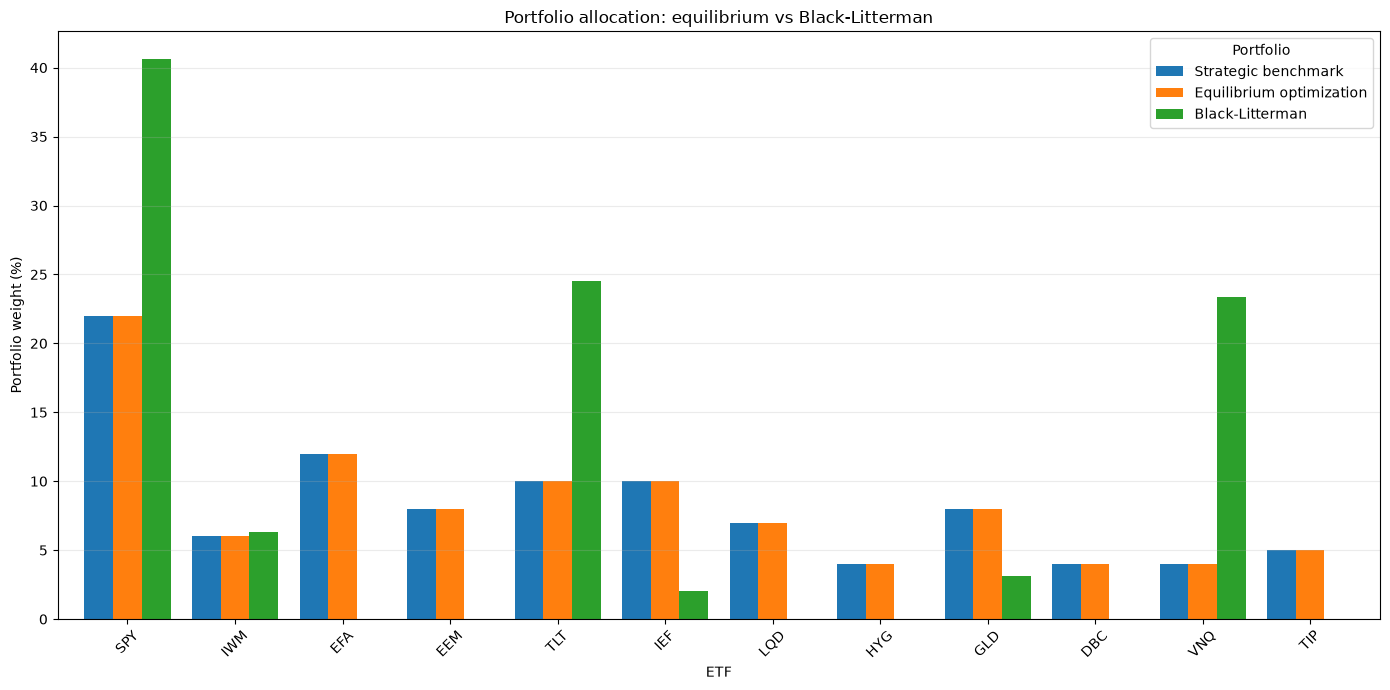

In [12]:
plot_weights = weights_comparison[
    [
        "Strategic benchmark",
        "Equilibrium optimization",
        "Black-Litterman",
    ]
].mul(100)

ax = plot_weights.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8,
)

ax.set_title(
    "Portfolio allocation: equilibrium vs Black-Litterman"
)

ax.set_xlabel("ETF")
ax.set_ylabel("Portfolio weight (%)")

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    title="Portfolio",
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.6. Propagación de las opiniones entre activos

Una característica importante de Black-Litterman es que las opiniones pueden modificar las rentabilidades esperadas de activos que no aparecen directamente en ellas.

Esto ocurre porque el modelo utiliza la matriz de covarianzas para relacionar las distintas exposiciones.

Por ejemplo, una opinión relativa favorable a SPY frente a EFA puede producir ajustes en los retornos posteriores de otros ETF de renta variable.

Estos efectos se denominan *spillovers*.

El ajuste de cada activo puede medirse mediante:

$$
\Delta \mu_i = \mu_{BL,i} - \Pi_i
$$

Un ajuste positivo indica que la rentabilidad posterior supera la implícita de equilibrio.

Un ajuste negativo indica que las opiniones reducen la expectativa respecto al equilibrio.

Los spillovers no constituyen nuevas opiniones independientes. Son consecuencias matemáticas de combinar las opiniones existentes con la estructura de covarianzas.

,Equilibrium return,Posterior return,Adjustment
Ticker,,,
VNQ,1.8290,2.2710,0.4430
TLT,-0.0480,0.2200,0.2680
IEF,0.0860,0.1720,0.0860
IWM,2.1920,2.2510,0.0580
LQD,0.3290,0.3670,0.0380
SPY,1.8180,1.8400,0.0220
TIP,0.2250,0.1960,-0.0290
HYG,0.7740,0.7110,-0.0630
GLD,1.3080,0.7950,-0.5120


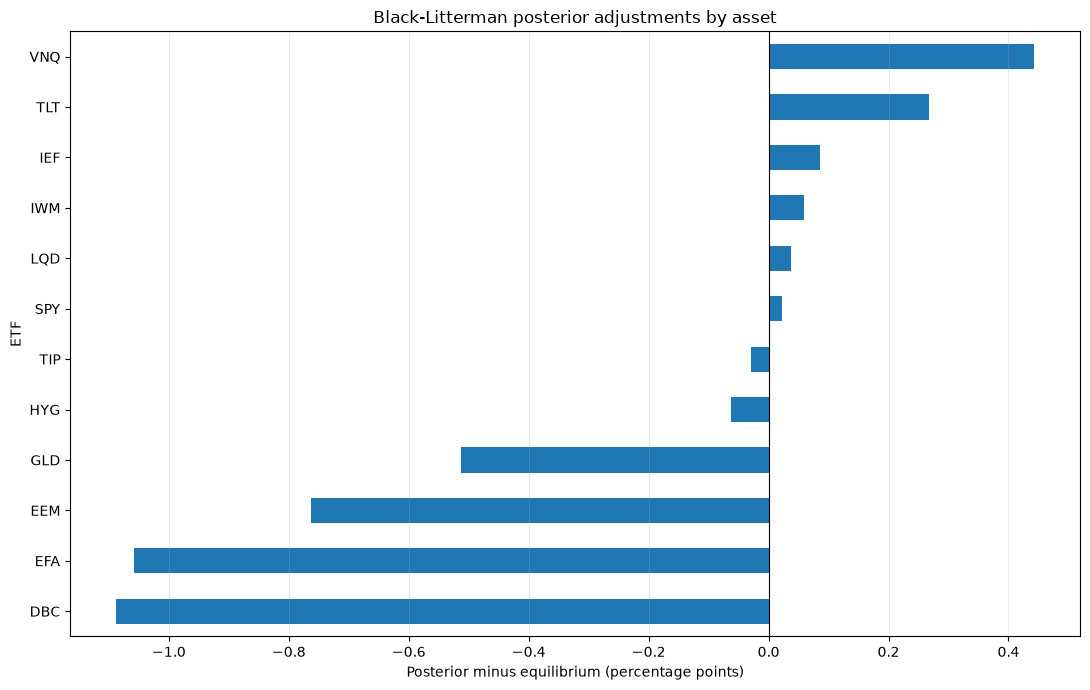

In [13]:
posterior_adjustment = (
    posterior - pi
).rename("Posterior adjustment")

spillover_table = pd.DataFrame({
    "Equilibrium return": pi,
    "Posterior return": posterior,
    "Adjustment": posterior_adjustment,
})

# Convert annualized returns to percentage points
spillover_table_pct = spillover_table * 100

display(
    spillover_table_pct
    .sort_values("Adjustment", ascending=False)
    .round(3)
)

# Visualize adjustments
ax = (
    spillover_table_pct["Adjustment"]
    .sort_values()
    .plot(
        kind="barh",
        figsize=(11, 7),
    )
)

ax.set_title(
    "Black-Litterman posterior adjustments by asset"
)

ax.set_xlabel(
    "Posterior minus equilibrium (percentage points)"
)

ax.set_ylabel("ETF")

ax.axvline(
    0,
    color="black",
    linewidth=0.8,
)

ax.grid(
    axis="x",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

In [14]:
# Assets explicitly involved in at least one view
direct_assets = P.columns[
    (P.abs() > 0).any(axis=0)
].tolist()

indirect_assets = [
    asset
    for asset in P.columns
    if asset not in direct_assets
]

print("Assets directly involved in views:")
print(direct_assets)

print("\nAssets not directly involved:")
print(indirect_assets)

if indirect_assets:

    indirect_adjustments = (
        posterior_adjustment
        .reindex(indirect_assets)
        .sort_values()
    )

    print("\nPosterior adjustments on indirect assets:")

    display(
        (indirect_adjustments * 100)
        .to_frame("Adjustment (pp)")
        .round(4)
    )

else:

    print(
        "\nAll assets participate directly in at least one view."
    )

Assets directly involved in views:
['SPY', 'EFA', 'GLD', 'DBC', 'VNQ']

Assets not directly involved:
['IWM', 'EEM', 'TLT', 'IEF', 'LQD', 'HYG', 'TIP']

Posterior adjustments on indirect assets:


,Adjustment (pp)
Ticker,
EEM,-0.7630
HYG,-0.0629
TIP,-0.0293
LQD,0.0376
IWM,0.0584
IEF,0.0864
TLT,0.2679


### 5.7. Interpretación de los resultados de Black-Litterman

La comparación entre los retornos implícitos y posteriores permite analizar cómo las opiniones modifican las expectativas del modelo.

El efecto sobre los pesos de la cartera depende de dos elementos:

1. Los cambios introducidos en las rentabilidades esperadas.
2. La estructura de riesgos y correlaciones considerada por el optimizador.

Por tanto, una mayor rentabilidad posterior no garantiza un incremento proporcional del peso del activo.

Asimismo, las opiniones pueden transmitir efectos indirectos sobre otros ETF mediante la matriz de covarianzas.

### Limitaciones del análisis

Los resultados deben interpretarse considerando las siguientes restricciones metodológicas:

- El benchmark es una cartera estratégica hipotética y no una cartera de mercado observada.
- El parámetro de aversión al riesgo se fija inicialmente en 2.5.
- Las confianzas de las opiniones son hipótesis de modelización.
- Las opiniones estratégicas se han elegido con conocimiento retrospectivo del período estudiado.
- La optimización emplea la covarianza histórica, sin incorporar explícitamente la incertidumbre posterior.
- No se permiten posiciones cortas ni apalancamiento.

Por ello, los resultados representan el comportamiento de una implementación concreta de Black-Litterman y no una evaluación universal del modelo.

### 5.8. Análisis de atribución de opiniones

Una cuestión fundamental de Black-Litterman es determinar hasta qué punto sus resultados dependen de las opiniones introducidas.

Para analizarlo se construyen cuatro configuraciones:

| Configuración | Opiniones utilizadas |
|---|---|
| BL-1 | Momentum relativo |
| BL-2A | Momentum + GLD supera a DBC |
| BL-2B | Momentum + SPY supera a EFA |
| BL-3 | Momentum + GLD/DBC + SPY/EFA |

Las cuatro configuraciones comparten:

- Universo de 12 ETF.
- Ventanas móviles de 36 meses.
- Rebalanceo trimestral.
- Benchmark estratégico.
- Aversión al riesgo de 2.5.
- Parámetro tau de 0.05.
- Restricciones long-only y sin apalancamiento.
- Motor de simulación y fechas de evaluación.

De esta forma, las diferencias entre configuraciones pueden atribuirse experimentalmente a los cambios en las opiniones.

#### Limitación metodológica

Las opiniones estratégicas se han formulado con conocimiento retrospectivo del período histórico.

Por ello, aunque las estimaciones y decisiones individuales respetan el procedimiento walk-forward, este análisis no demuestra capacidad predictiva genuina fuera de muestra de las opiniones seleccionadas.

Su principal finalidad es estudiar el comportamiento del modelo y la influencia de las hipótesis de inversión.

In [15]:
from quantmgmt.backtesting.comparison import (
    run_strategy_comparison,
)

from quantmgmt.backtesting.metrics import (
    evaluate_backtest,
)

BL_CONFIGURATIONS = {
    "BL-1": {
        "include_gld_view": False,
        "include_spy_view": False,
    },
    "BL-2A": {
        "include_gld_view": True,
        "include_spy_view": False,
    },
    "BL-2B": {
        "include_gld_view": False,
        "include_spy_view": True,
    },
    "BL-3": {
        "include_gld_view": True,
        "include_spy_view": True,
    },
}

bl_attribution_rows = []

bl_comparisons = {}

for name, configuration in BL_CONFIGURATIONS.items():

    print(f"Calculando {name}...")

    comparison = run_strategy_comparison(
        returns=returns,
        market_weights=market_weights,
        risk_free_rate=0.0,
        risk_aversion=2.5,
        tau=0.05,
        momentum_months=12,
        expected_spread=0.03,
        confidence=0.60,
        lookback_months=36,
        initial_capital=100_000.0,
        transaction_cost_bps=0.0,
        bl_view_mode="three",
        **configuration,
    )

    metrics = evaluate_backtest(
        comparison_result=comparison,
        risk_free_rate=0.0,
        periods_per_year=252,
    )

    bl = metrics.loc["black_litterman"]

    bl_attribution_rows.append({
        "Configuration": name,
        "CAGR": bl["cagr"],
        "Volatility": bl["volatility"],
        "Sharpe": bl["sharpe"],
        "Max Drawdown": bl["max_drawdown"],
        "Annual Turnover": bl["annual_turnover"],
        "Effective Assets": bl["average_effective_assets"],
        "Final NAV": comparison["nav"][
            "black_litterman"
        ].iloc[-1],
    })

    bl_comparisons[name] = comparison

bl_attribution = pd.DataFrame(
    bl_attribution_rows
).set_index("Configuration")

display(bl_attribution.round(4))

Calculando BL-1...
Calculando BL-2A...
Calculando BL-2B...
Calculando BL-3...


,CAGR,Volatility,Sharpe,Max Drawdown,Annual Turnover,Effective Assets,Final NAV
Configuration,,,,,,,
BL-1,0.0522,0.1064,0.5320,-0.2362,1.9742,6.7094,180201.6316
BL-2A,0.0580,0.1027,0.6002,-0.2184,1.9492,6.2619,191949.9089
BL-2B,0.0709,0.1072,0.6927,-0.2083,1.6423,3.5470,220888.6599
BL-3,0.0746,0.1027,0.7519,-0.1899,1.6109,3.6142,229830.5443


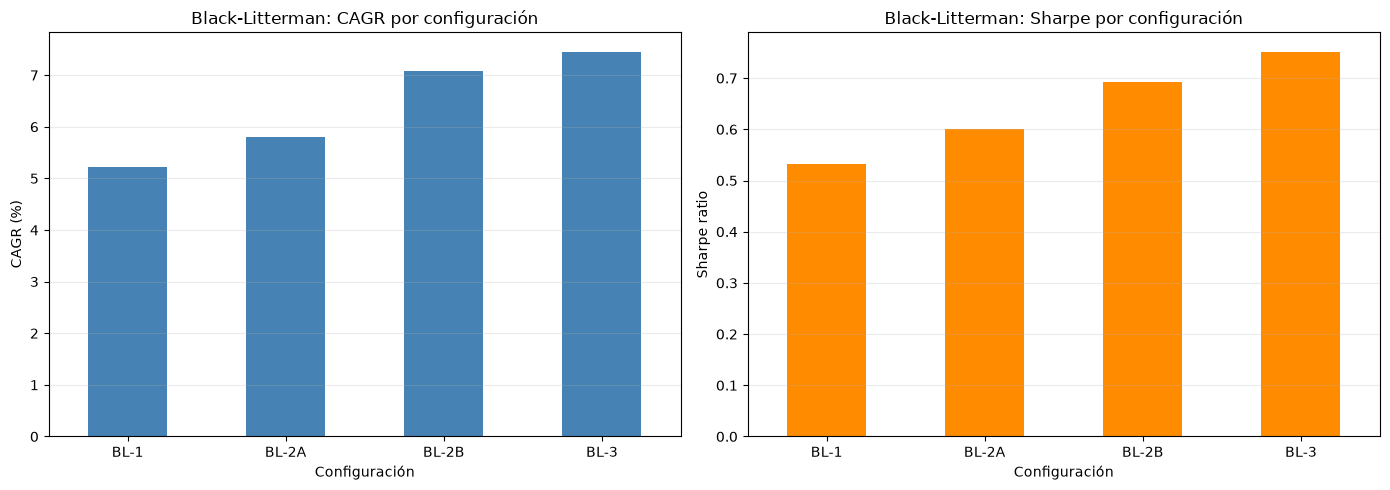

In [16]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

# CAGR comparison
bl_attribution["CAGR"].mul(100).plot(
    kind="bar",
    ax=axes[0],
    color="steelblue",
)

axes[0].set_title(
    "Black-Litterman: CAGR por configuración"
)

axes[0].set_ylabel("CAGR (%)")
axes[0].set_xlabel("Configuración")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.25)

# Sharpe comparison
bl_attribution["Sharpe"].plot(
    kind="bar",
    ax=axes[1],
    color="darkorange",
)

axes[1].set_title(
    "Black-Litterman: Sharpe por configuración"
)

axes[1].set_ylabel("Sharpe ratio")
axes[1].set_xlabel("Configuración")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [17]:
baseline_cagr = bl_attribution.loc["BL-1", "CAGR"]

attribution_effects = pd.Series({
    "GLD/DBC": (
        bl_attribution.loc["BL-2A", "CAGR"]
        - baseline_cagr
    ),
    "SPY/EFA": (
        bl_attribution.loc["BL-2B", "CAGR"]
        - baseline_cagr
    ),
    "Combined": (
        bl_attribution.loc["BL-3", "CAGR"]
        - baseline_cagr
    ),
})

interaction = (
    attribution_effects["Combined"]
    - attribution_effects["GLD/DBC"]
    - attribution_effects["SPY/EFA"]
)

print("Incremental CAGR effects (percentage points):")

display(
    (attribution_effects * 100)
    .to_frame("CAGR improvement (pp)")
    .round(3)
)

print(
    "Interaction effect (pp):",
    round(interaction * 100, 3),
)

Incremental CAGR effects (percentage points):


,CAGR improvement (pp)
GLD/DBC,0.5760
SPY/EFA,1.8680
Combined,2.2350


Interaction effect (pp): -0.208


### 5.9. Sensibilidad de Black-Litterman

El comportamiento del modelo depende de parámetros que reflejan hipótesis sobre el equilibrio de mercado y la fiabilidad de las opiniones.

Analizamos dos dimensiones:

**Aversión al riesgo**

$$
\delta \in \{1.5,\ 2.5,\ 4.0\}
$$

Este parámetro determina la magnitud de las primas de riesgo implícitas:

$$
\Pi = \delta \Sigma w_{mkt}
$$

**Confianza en momentum**

$$
c \in \{0.40,\ 0.60,\ 0.80\}
$$

Una mayor confianza reduce la incertidumbre atribuida a la opinión dinámica.

Las dos opiniones estratégicas mantienen una confianza del 55 %.

Se evalúan las nueve combinaciones posibles utilizando el mismo procedimiento walk-forward.

El objetivo no es seleccionar retrospectivamente los parámetros que maximizan el Sharpe, sino determinar la estabilidad de los resultados frente a hipótesis alternativas razonables.

In [18]:
from itertools import product

RISK_AVERSIONS = [1.5, 2.5, 4.0]
MOMENTUM_CONFIDENCES = [0.40, 0.60, 0.80]

sensitivity_rows = []

for delta, confidence in product(
    RISK_AVERSIONS,
    MOMENTUM_CONFIDENCES,
):

    print(
        f"δ={delta}, "
        f"confianza={confidence:.0%}"
    )

    # Reuse the baseline BL-3 experiment.
    if delta == 2.5 and confidence == 0.60:

        comparison = bl_comparisons["BL-3"]

    else:

        comparison = run_strategy_comparison(
            returns=returns,
            market_weights=market_weights,
            risk_free_rate=0.0,
            risk_aversion=delta,
            tau=0.05,
            momentum_months=12,
            expected_spread=0.03,
            confidence=confidence,
            lookback_months=36,
            initial_capital=100_000.0,
            transaction_cost_bps=0.0,
            bl_view_mode="three",
            include_gld_view=True,
            include_spy_view=True,
        )

    metrics = evaluate_backtest(
        comparison_result=comparison,
        risk_free_rate=0.0,
        periods_per_year=252,
    )

    bl = metrics.loc["black_litterman"]

    sensitivity_rows.append({
        "Delta": delta,
        "Momentum Confidence": confidence,
        "CAGR": bl["cagr"],
        "Sharpe": bl["sharpe"],
        "Max Drawdown": bl["max_drawdown"],
    })

bl_sensitivity = pd.DataFrame(
    sensitivity_rows
)

print("\nCAGR (%)")

display(
    (
        bl_sensitivity.pivot(
            index="Delta",
            columns="Momentum Confidence",
            values="CAGR",
        ) * 100
    ).round(2)
)

print("\nSharpe")

display(
    bl_sensitivity.pivot(
        index="Delta",
        columns="Momentum Confidence",
        values="Sharpe",
    ).round(3)
)

print("\nMaximum Drawdown (%)")

display(
    (
        bl_sensitivity.pivot(
            index="Delta",
            columns="Momentum Confidence",
            values="Max Drawdown",
        ) * 100
    ).round(2)
)

δ=1.5, confianza=40%
δ=1.5, confianza=60%
δ=1.5, confianza=80%
δ=2.5, confianza=40%
δ=2.5, confianza=60%
δ=2.5, confianza=80%
δ=4.0, confianza=40%
δ=4.0, confianza=60%
δ=4.0, confianza=80%

CAGR (%)


Momentum Confidence,0.4000,0.6000,0.8000
Delta,,,
1.5000,7.6900,6.9700,6.3000
2.5000,7.9600,7.4600,6.8400
4.0000,8.0300,7.6700,7.2900



Sharpe


Momentum Confidence,0.4000,0.6000,0.8000
Delta,,,
1.5000,0.7540,0.6640,0.5750
2.5000,0.8140,0.7520,0.6770
4.0000,0.8490,0.8140,0.7720



Maximum Drawdown (%)


Momentum Confidence,0.4000,0.6000,0.8000
Delta,,,
1.5000,-19.0400,-21.4700,-24.1400
2.5000,-20.0900,-18.9900,-19.4100
4.0000,-20.7000,-20.0300,-19.2800


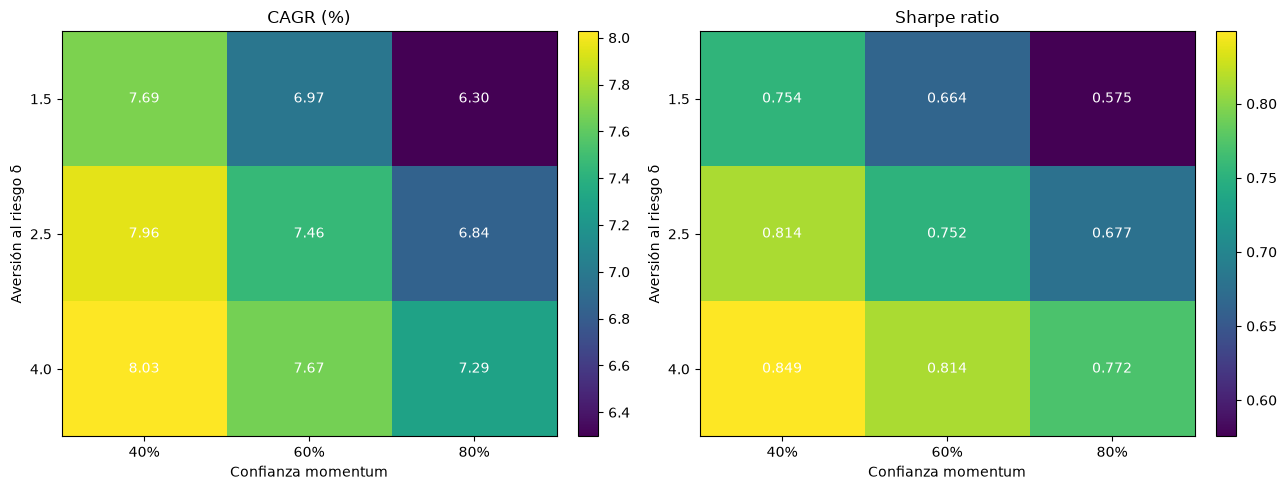

In [19]:
cagr_matrix = bl_sensitivity.pivot(
    index="Delta",
    columns="Momentum Confidence",
    values="CAGR",
) * 100

sharpe_matrix = bl_sensitivity.pivot(
    index="Delta",
    columns="Momentum Confidence",
    values="Sharpe",
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

matrices = [
    (cagr_matrix, "CAGR (%)", ".2f"),
    (sharpe_matrix, "Sharpe ratio", ".3f"),
]

for ax, (matrix, title, fmt) in zip(
    axes,
    matrices,
):

    image = ax.imshow(
        matrix.to_numpy(),
        cmap="viridis",
        aspect="auto",
    )

    ax.set_xticks(
        range(len(matrix.columns)),
        labels=[f"{c:.0%}" for c in matrix.columns],
    )

    ax.set_yticks(
        range(len(matrix.index)),
        labels=matrix.index,
    )

    ax.set_xlabel("Confianza momentum")
    ax.set_ylabel("Aversión al riesgo δ")
    ax.set_title(title)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):

            value = matrix.iloc[i, j]

            ax.text(
                j,
                i,
                format(value, fmt),
                ha="center",
                va="center",
                color="white",
            )

    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04,
    )

plt.tight_layout()
plt.show()

### 5.10. Interpretación del parámetro tau

El parámetro $\tau$ representa la incertidumbre asociada a las rentabilidades implícitas de equilibrio.

En nuestra implementación, la incertidumbre de las opiniones se construye como:

$$
\Omega_i =
\frac{1-c_i}{c_i}
\left(P\tau\Sigma P^\top\right)_{ii}
$$

Esto significa que la matriz $\Omega$ es proporcional a $\tau$.

En la fórmula de los retornos posteriores:

$$
\mu_{BL}
=
\Pi+
\tau\Sigma P^\top
\left(
P\tau\Sigma P^\top+\Omega
\right)^{-1}
(Q-P\Pi)
$$

el factor $\tau$ aparece tanto fuera como dentro de la inversión matricial.

Cuando $\Omega$ se construye proporcionalmente a $\tau$, ese factor se cancela algebraicamente.

Por tanto, en nuestra parametrización:

**Modificar tau sin cambiar la regla de construcción de Omega no debería modificar las medias posteriores de Black-Litterman.**

Esto no implica que tau sea irrelevante en todas las formulaciones del modelo.

Por ejemplo, puede influir cuando Omega se especifica independientemente de tau o cuando se incorpora la incertidumbre posterior en la matriz utilizada para optimizar.

In [20]:
TAU_VALUES = [0.01, 0.05, 0.10]

posterior_by_tau = {}

for tau_value in TAU_VALUES:

    omega_tau = build_omega(
        covariance_matrix=historical_cov,
        P=P,
        tau=tau_value,
        confidences=confidences,
    )

    posterior_tau = posterior_returns(
        equilibrium_returns=pi,
        covariance_matrix=historical_cov,
        P=P,
        Q=Q,
        omega=omega_tau,
        tau=tau_value,
    )

    posterior_by_tau[tau_value] = posterior_tau

tau_comparison = pd.DataFrame(
    posterior_by_tau
)

display(tau_comparison.round(8))

# Confirm numerical invariance
reference = tau_comparison[0.05]

for tau_value in TAU_VALUES:

    np.testing.assert_allclose(
        tau_comparison[tau_value].to_numpy(),
        reference.to_numpy(),
        rtol=1e-8,
        atol=1e-10,
    )

print(
    "Verificado: las medias posteriores son "
    "invariantes a tau bajo esta parametrización."
)

,0.0100,0.0500,0.1000
Ticker,,,
SPY,0.0184,0.0184,0.0184
IWM,0.0225,0.0225,0.0225
EFA,0.0120,0.0120,0.0120
EEM,0.0196,0.0196,0.0196
TLT,0.0022,0.0022,0.0022
IEF,0.0017,0.0017,0.0017
LQD,0.0037,0.0037,0.0037
HYG,0.0071,0.0071,0.0071
GLD,0.0080,0.0080,0.0080


Verificado: las medias posteriores son invariantes a tau bajo esta parametrización.


## 6. Hierarchical Risk Parity

Hierarchical Risk Parity (HRP) es una metodología de construcción de carteras basada en técnicas de aprendizaje no supervisado y asignación jerárquica del capital.

A diferencia de la optimización media-varianza tradicional, HRP no necesita invertir directamente la matriz de covarianzas para obtener los pesos de la cartera.

El procedimiento comprende cinco etapas:

1. Construcción de la matriz de correlaciones.
2. Transformación de correlaciones en distancias.
3. Clustering jerárquico.
4. Cuasi-diagonalización de la matriz de correlaciones.
5. Asignación mediante bisección recursiva.

### Motivación

La optimización media-varianza puede producir carteras concentradas e inestables cuando las estimaciones de rentabilidad y covarianza contienen errores.

HRP utiliza la estructura de similitudes entre activos para organizar la asignación de capital.

No garantiza obtener una cartera de mínima volatilidad ni igualar las contribuciones individuales al riesgo.

Su objetivo es construir una asignación basada en la estructura jerárquica de los activos y en las varianzas de sus agrupaciones.

En esta práctica implementamos HRP desde cero, utilizando SciPy exclusivamente para el clustering jerárquico.

In [21]:
from quantmgmt.optimizers.hrp import (
    correlation_distance,
    hierarchical_clustering,
    quasi_diagonalize,
    hrp_weights,
    inverse_volatility_weights,
)

# Last completed rebalance in the experiment
hrp_date = rebalance_dates[-1]

hrp_window_start = (
    hrp_date - pd.DateOffset(months=36)
)

hrp_window = returns.loc[
    (returns.index > hrp_window_start)
    & (returns.index <= hrp_date)
].copy()

# Annualized covariance
hrp_covariance = hrp_window.cov() * 252

# Correlation matrix
hrp_correlation = hrp_window.corr()

print("Fecha de rebalanceo:", hrp_date.date())
print("Inicio de ventana:", hrp_window_start.date())
print("Observaciones:", len(hrp_window))

display(hrp_correlation.round(3))

Fecha de rebalanceo: 2026-09-30
Inicio de ventana: 2023-09-30
Observaciones: 752


Ticker,SPY,IWM,EFA,EEM,TLT,IEF,LQD,HYG,GLD,DBC,VNQ,TIP
Ticker,,,,,,,,,,,,
SPY,1.0000,0.8070,0.7600,0.6800,0.1520,0.0950,0.3670,0.7490,0.1780,0.0830,0.5170,0.1850
IWM,0.8070,1.0000,0.7170,0.6230,0.2180,0.1890,0.4180,0.7500,0.2120,0.0530,0.6330,0.2540
EFA,0.7600,0.7170,1.0000,0.7910,0.2610,0.2650,0.4620,0.7150,0.3740,0.0240,0.5560,0.2980
EEM,0.6800,0.6230,0.7910,1.0000,0.1770,0.1820,0.3500,0.5800,0.3970,0.0850,0.3350,0.2140
TLT,0.1520,0.2180,0.2610,0.1770,1.0000,0.9220,0.9140,0.5190,0.1370,-0.1870,0.4370,0.8420
IEF,0.0950,0.1890,0.2650,0.1820,0.9220,1.0000,0.9010,0.5230,0.2160,-0.2140,0.4260,0.8960
LQD,0.3670,0.4180,0.4620,0.3500,0.9140,0.9010,1.0000,0.7390,0.2110,-0.1400,0.5560,0.8460
HYG,0.7490,0.7500,0.7150,0.5800,0.5190,0.5230,0.7390,1.0000,0.2290,0.0240,0.6700,0.5600
GLD,0.1780,0.2120,0.3740,0.3970,0.1370,0.2160,0.2110,0.2290,1.0000,0.2930,0.1620,0.2320


### 6.1. De correlaciones a distancias

El clustering jerárquico necesita una medida de distancia entre activos.

Utilizamos:

$$
d_{i,j} =
\sqrt{\frac{1-\rho_{i,j}}{2}}
$$

Donde $\rho_{i,j}$ representa la correlación entre los retornos de los activos $i$ y $j$.

Esta transformación presenta las siguientes propiedades:

- Correlación +1: distancia 0.
- Correlación 0: distancia aproximadamente 0.707.
- Correlación -1: distancia 1.

Por tanto, dos activos con retornos muy correlacionados tendrán una distancia pequeña.

Esta medida permite aplicar técnicas de clustering para identificar grupos de activos con comportamientos relacionados.

Ticker,SPY,IWM,EFA,EEM,TLT,IEF,LQD,HYG,GLD,DBC,VNQ,TIP
Ticker,,,,,,,,,,,,
SPY,0.0000,0.3100,0.3460,0.4000,0.6510,0.6730,0.5620,0.3540,0.6410,0.6770,0.4920,0.6380
IWM,0.3100,0.0000,0.3760,0.4340,0.6250,0.6370,0.5390,0.3540,0.6280,0.6880,0.4280,0.6110
EFA,0.3460,0.3760,0.0000,0.3240,0.6080,0.6060,0.5190,0.3780,0.5600,0.6990,0.4710,0.5920
EEM,0.4000,0.4340,0.3240,0.0000,0.6410,0.6400,0.5700,0.4580,0.5490,0.6770,0.5770,0.6270
TLT,0.6510,0.6250,0.6080,0.6410,0.0000,0.1970,0.2070,0.4910,0.6570,0.7700,0.5310,0.2810
IEF,0.6730,0.6370,0.6060,0.6400,0.1970,0.0000,0.2220,0.4880,0.6260,0.7790,0.5360,0.2280
LQD,0.5620,0.5390,0.5190,0.5700,0.2070,0.2220,0.0000,0.3610,0.6280,0.7550,0.4710,0.2770
HYG,0.3540,0.3540,0.3780,0.4580,0.4910,0.4880,0.3610,0.0000,0.6210,0.6980,0.4060,0.4690
GLD,0.6410,0.6280,0.5600,0.5490,0.6570,0.6260,0.6280,0.6210,0.0000,0.5950,0.6470,0.6190


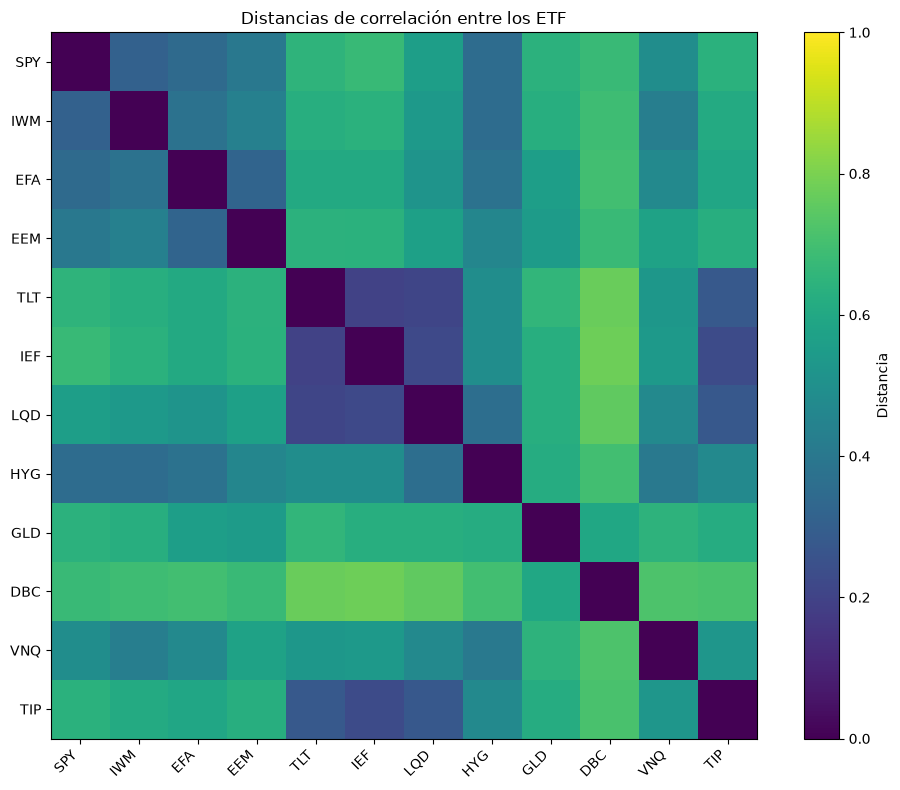

In [22]:
hrp_distance = correlation_distance(
    hrp_correlation
)

display(hrp_distance.round(3))

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    hrp_distance.to_numpy(),
    cmap="viridis",
    vmin=0,
    vmax=1,
)

ax.set_xticks(
    range(len(hrp_distance.columns)),
    labels=hrp_distance.columns,
    rotation=45,
    ha="right",
)

ax.set_yticks(
    range(len(hrp_distance.index)),
    labels=hrp_distance.index,
)

ax.set_title(
    "Distancias de correlación entre los ETF"
)

fig.colorbar(
    im,
    ax=ax,
    label="Distancia",
)

plt.tight_layout()
plt.show()

### 6.2. Clustering jerárquico

El clustering jerárquico agrupa los activos a partir de sus distancias.

En esta implementación utilizamos el método **single linkage**.

Este criterio define la distancia entre dos grupos como la menor distancia existente entre un activo de cada grupo.

Se utiliza además `optimal_ordering=True`, que reorganiza las hojas del dendrograma sin modificar las fusiones del árbol.

Esta ordenación es relevante para nuestro procedimiento posterior de cuasi-diagonalización y bisección recursiva.

El resultado del clustering se representa mediante un dendrograma.

Cada unión del árbol muestra la distancia a la que se agrupan dos activos o conjuntos de activos.

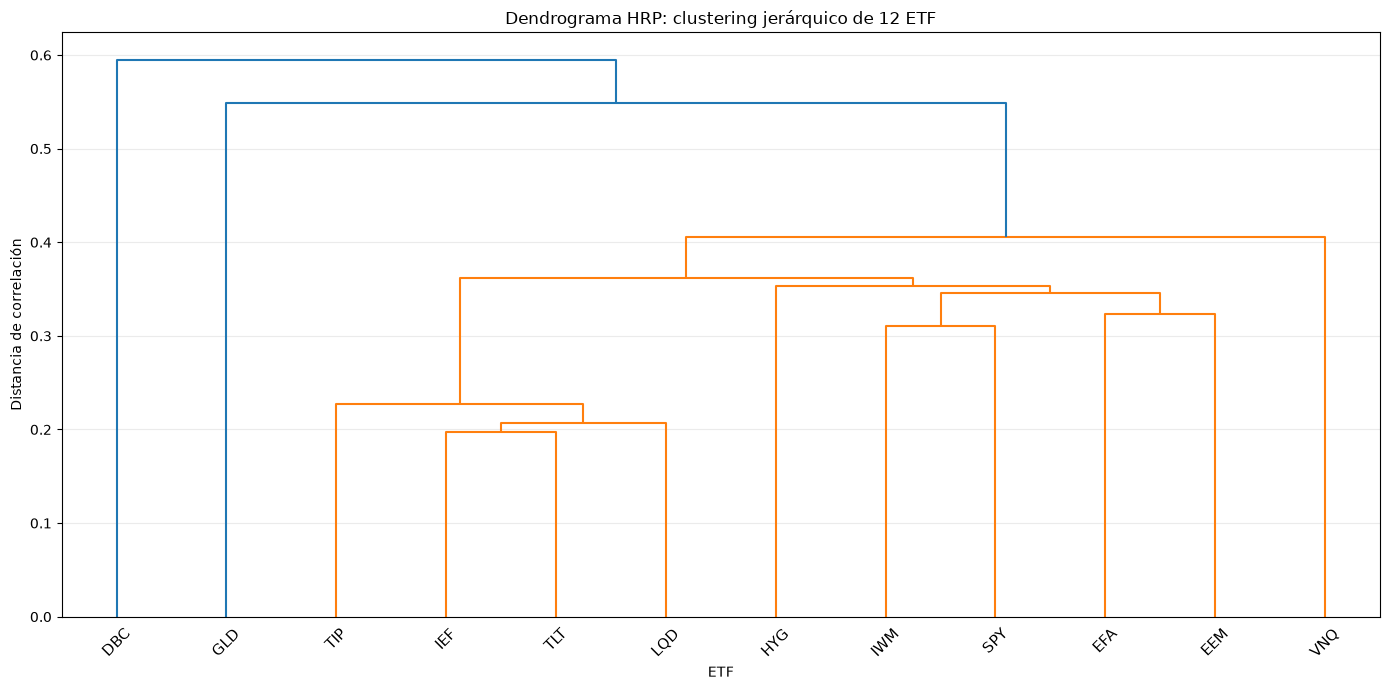

In [23]:
from scipy.cluster.hierarchy import dendrogram

linkage_matrix = hierarchical_clustering(
    distance_matrix=hrp_distance,
    method="single",
)

fig, ax = plt.subplots(figsize=(14, 7))

dendrogram(
    linkage_matrix,
    labels=hrp_correlation.index.tolist(),
    leaf_rotation=45,
    leaf_font_size=11,
    ax=ax,
)

ax.set_title(
    "Dendrograma HRP: clustering jerárquico de 12 ETF"
)

ax.set_xlabel("ETF")
ax.set_ylabel("Distancia de correlación")

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

### 6.3. Cuasi-diagonalización

Después del clustering se reorganiza la matriz de correlaciones siguiendo el orden de las hojas del dendrograma.

Este proceso se denomina cuasi-diagonalización.

Su finalidad es situar próximos en la matriz aquellos activos que presentan relaciones similares según la estructura jerárquica.

No se trata de una diagonalización matricial convencional.

La matriz resultante conserva las correlaciones originales, pero modifica el orden de filas y columnas.

La reorganización permite identificar visualmente bloques de activos y proporciona el orden utilizado posteriormente en la bisección recursiva.

Orden de cuasi-diagonalización:
DBC → GLD → TIP → IEF → TLT → LQD → HYG → IWM → SPY → EFA → EEM → VNQ


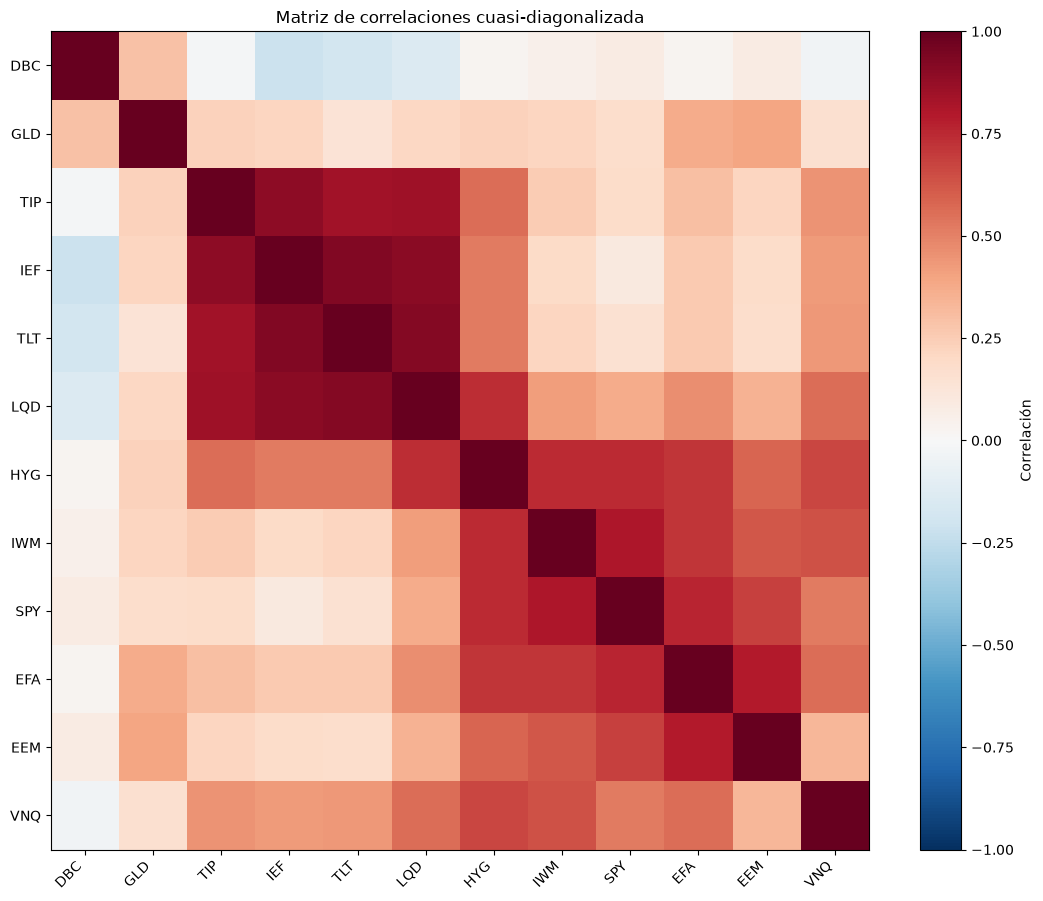

In [24]:
ordered_assets = quasi_diagonalize(
    linkage_matrix,
    hrp_correlation.index,
)

reordered_correlation = hrp_correlation.loc[
    ordered_assets,
    ordered_assets,
]

print("Orden de cuasi-diagonalización:")

print(
    " → ".join(ordered_assets)
)

fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(
    reordered_correlation.to_numpy(),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(
    range(len(ordered_assets)),
    labels=ordered_assets,
    rotation=45,
    ha="right",
)

ax.set_yticks(
    range(len(ordered_assets)),
    labels=ordered_assets,
)

ax.set_title(
    "Matriz de correlaciones cuasi-diagonalizada"
)

fig.colorbar(
    im,
    ax=ax,
    label="Correlación",
)

plt.tight_layout()
plt.show()

### 6.4. Asignación de capital mediante bisección recursiva

Una vez obtenida la secuencia cuasi-diagonalizada, HRP divide recursivamente los activos en grupos.

En cada división se calcula la varianza de los dos subconjuntos.

Para estimar la varianza de cada grupo se utiliza una cartera interna ponderada por inversa de varianza.

Dados dos grupos $A$ y $B$, sus varianzas son:

$$
V_A = w_A^\top \Sigma_A w_A
$$

$$
V_B = w_B^\top \Sigma_B w_B
$$

La fracción de capital asignada al grupo $A$ es:

$$
\alpha_A =
\frac{V_B}{V_A+V_B}
$$

Y la correspondiente al grupo $B$:

$$
\alpha_B =
\frac{V_A}{V_A+V_B}
$$

De esta manera, el grupo con mayor varianza recibe una proporción menor del capital.

El procedimiento continúa dividiendo los grupos hasta obtener los pesos individuales de todos los ETF.

Esta construcción no requiere invertir la matriz de covarianzas completa.

### Diferencia frente a Equal Risk Contribution

HRP no impone que todos los activos aporten exactamente el mismo porcentaje de riesgo.

Su asignación depende de la estructura de agrupaciones y de las varianzas estimadas en cada bifurcación.

Comparación de pesos:


,HRP,Inverse Volatility
Ticker,,
TIP,0.4117,0.1851
HYG,0.2712,0.1681
IEF,0.1160,0.1330
LQD,0.0530,0.1191
DBC,0.0315,0.0489
EFA,0.0280,0.0553
GLD,0.0185,0.0392
VNQ,0.0176,0.0506
SPY,0.0166,0.0552


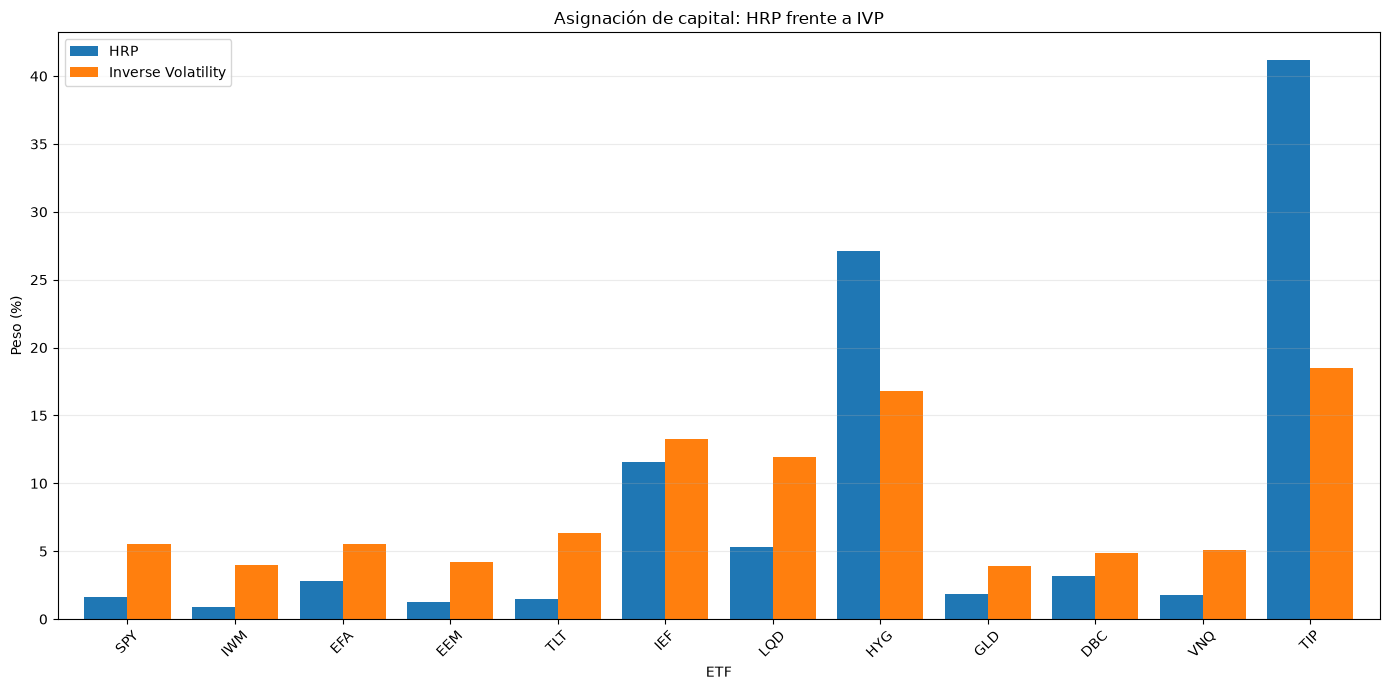

In [25]:
# HRP allocation
weights_hrp = hrp_weights(
    covariance_matrix=hrp_covariance,
)

# Naive inverse-volatility allocation
weights_ivp = inverse_volatility_weights(
    covariance_matrix=hrp_covariance,
)

# Align results
weights_hrp = weights_hrp.reindex(
    hrp_covariance.index
)

weights_ivp = weights_ivp.reindex(
    hrp_covariance.index
)

allocation_comparison = pd.DataFrame({
    "HRP": weights_hrp,
    "Inverse Volatility": weights_ivp,
})

print("Comparación de pesos:")

display(
    allocation_comparison
    .sort_values("HRP", ascending=False)
    .round(4)
)

# Validation
np.testing.assert_allclose(
    allocation_comparison.sum(axis=0).to_numpy(),
    np.ones(2),
    atol=1e-8,
)

assert (
    allocation_comparison >= -1e-8
).all().all()

# Plot
ax = (
    allocation_comparison * 100
).plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8,
)

ax.set_title(
    "Asignación de capital: HRP frente a IVP"
)

ax.set_xlabel("ETF")
ax.set_ylabel("Peso (%)")

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.5. Contribuciones individuales al riesgo

La distribución del capital no coincide necesariamente con la distribución del riesgo.

Dos activos pueden tener el mismo peso y aportar cantidades muy diferentes a la volatilidad de una cartera, debido a sus volatilidades individuales y a sus correlaciones con el resto.

La volatilidad de una cartera viene determinada por:

$$
\sigma_p = \sqrt{w^\top\Sigma w}
$$

La contribución absoluta del activo $i$ a la volatilidad es:

$$
RC_i = \frac{w_i(\Sigma w)_i}{\sigma_p}
$$

La contribución porcentual es:

$$
RC_i^{\%} =
\frac{w_i(\Sigma w)_i}{w^\top\Sigma w}
$$

Estas contribuciones presentan una propiedad importante:

$$
\sum_{i=1}^{N} RC_i^{\%}=1
$$

Una contribución porcentual negativa es posible cuando un activo reduce el riesgo total de la cartera gracias a su relación con las restantes posiciones.

### Objetivo del análisis

Comparamos las contribuciones individuales al riesgo de HRP e IVP utilizando:

- La misma matriz de covarianzas anualizada.
- La misma ventana histórica de 36 meses.
- La misma fecha de rebalanceo.
- Las asignaciones calculadas por cada metodología.

Así podemos estudiar si la estructura jerárquica de HRP proporciona una distribución del riesgo diferente a la obtenida mediante inversa de volatilidad.

Es importante recordar que HRP no pretende igualar exactamente las contribuciones individuales al riesgo.

In [26]:
def percentage_risk_contributions(
    weights: pd.Series,
    covariance: pd.DataFrame,
) -> pd.Series:
    """
    Percentage contributions to portfolio volatility.

    Contributions sum to one, but individual
    contributions may be negative.
    """

    assets = covariance.index

    w = weights.reindex(assets).to_numpy(dtype=float)

    sigma = covariance.loc[
        assets, assets
    ].to_numpy(dtype=float)

    portfolio_variance = float(w @ sigma @ w)

    if portfolio_variance <= 0:
        raise ValueError(
            "Portfolio variance must be positive"
        )

    contributions = (
        w * (sigma @ w)
    ) / portfolio_variance

    return pd.Series(
        contributions,
        index=assets,
        name="risk_contribution",
    )


# HRP risk contributions
rc_hrp = percentage_risk_contributions(
    weights_hrp,
    hrp_covariance,
)

# IVP risk contributions
rc_ivp = percentage_risk_contributions(
    weights_ivp,
    hrp_covariance,
)

# Validate the Euler decomposition
np.testing.assert_allclose(
    rc_hrp.sum(),
    1.0,
    atol=1e-8,
)

np.testing.assert_allclose(
    rc_ivp.sum(),
    1.0,
    atol=1e-8,
)

risk_comparison = pd.DataFrame({
    "HRP": rc_hrp,
    "Inverse Volatility": rc_ivp,
})

print("Contribuciones porcentuales al riesgo:")

display(
    (
        risk_comparison * 100
    ).sort_values(
        "HRP",
        ascending=False,
    ).round(2)
)

Contribuciones porcentuales al riesgo:


,HRP,Inverse Volatility
Ticker,,
TIP,32.8100,9.0500
HYG,23.7100,11.0900
IEF,11.9500,8.4900
LQD,6.8200,10.4100
EFA,5.6500,9.7800
VNQ,3.9500,8.9700
GLD,3.1900,5.7200
TLT,3.1200,8.4700
SPY,2.8700,8.7600


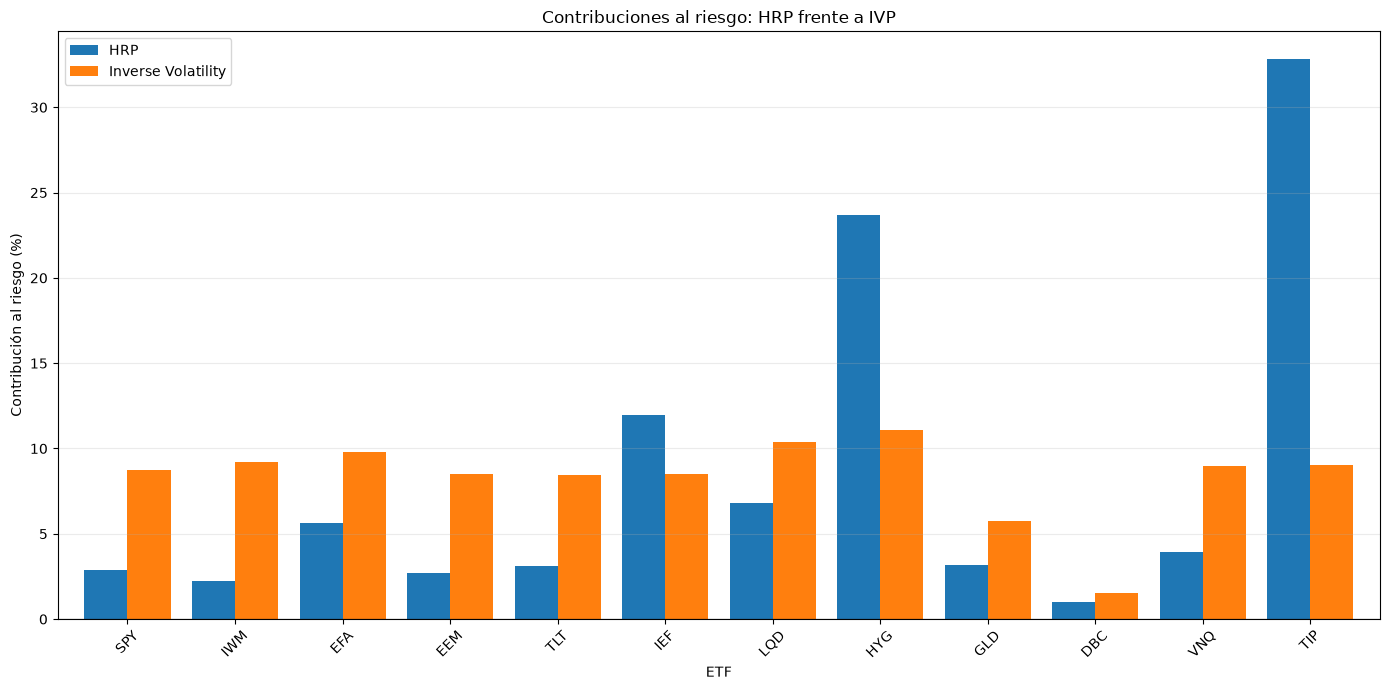

In [27]:
# Percentage risk contributions
risk_plot = risk_comparison.mul(100)

ax = risk_plot.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8,
)

ax.set_title(
    "Contribuciones al riesgo: HRP frente a IVP"
)

ax.set_xlabel("ETF")
ax.set_ylabel("Contribución al riesgo (%)")

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
def effective_number(weights: pd.Series) -> float:
    """
    Effective number based on the Herfindahl index.
    """

    return 1.0 / float(
        np.square(weights.to_numpy()).sum()
    )


risk_summary = pd.DataFrame(
    {
        "HRP": {
            "Largest capital weight":
                weights_hrp.max(),

            "Largest positive risk contribution":
                rc_hrp.max(),

            "Effective assets":
                effective_number(weights_hrp),

            "Portfolio volatility":
                np.sqrt(
                    weights_hrp
                    @ hrp_covariance
                    @ weights_hrp
                ),
        },

        "IVP": {
            "Largest capital weight":
                weights_ivp.max(),

            "Largest positive risk contribution":
                rc_ivp.max(),

            "Effective assets":
                effective_number(weights_ivp),

            "Portfolio volatility":
                np.sqrt(
                    weights_ivp
                    @ hrp_covariance
                    @ weights_ivp
                ),
        },
    }
)

display(risk_summary.round(4))

,HRP,IVP
Largest capital weight,0.4117,0.1851
Largest positive risk contribution,0.3281,0.1109
Effective assets,3.8107,8.7446
Portfolio volatility,0.0495,0.0674


### 6.6. Comparación de HRP frente a Inverse Volatility Portfolio

Para evaluar la utilidad de HRP se compara su comportamiento con una estrategia ingenua basada en la inversa de volatilidad.

La cartera IVP utiliza:

$$
w_i =
\frac{1/\sigma_i}
{\sum_{j=1}^{N}1/\sigma_j}
$$

A diferencia de HRP, este método no incorpora directamente las correlaciones entre activos al determinar sus pesos.

### Metodología

Ambas estrategias utilizan:

- Los mismos 12 ETF.
- Ventanas históricas móviles de 36 meses.
- Rebalanceos trimestrales.
- Posiciones exclusivamente largas.
- Capital inicial de 100.000 USD.
- Costes de transacción nulos en el escenario base.
- Tipo libre de riesgo del 0 % para calcular el Sharpe.

Los pesos calculados al cierre de cada rebalanceo se aplican a partir de la siguiente sesión.

Se estudian cuatro indicadores principales:

1. CAGR.
2. Volatilidad anualizada.
3. Sharpe ratio.
4. Maximum Drawdown.

También se comparan el capital final y el número efectivo medio de activos.

Esta comparación permite comprobar si la incorporación de correlaciones y clustering produce ventajas frente a una regla de asignación más sencilla.

In [29]:
from quantmgmt.backtesting.walk_forward import (
    generate_walk_forward_weights,
)

from quantmgmt.backtesting.engine import (
    simulate_portfolio,
)

from quantmgmt.backtesting.metrics import (
    concentration_metrics,
)

from quantmgmt.risk.returns import cagr
from quantmgmt.risk.volatility import annualized_volatility
from quantmgmt.risk.ratios import sharpe_ratio
from quantmgmt.risk.drawdown import max_drawdown


def hrp_weight_function(window, date):

    covariance = window.cov() * 252

    return hrp_weights(
        covariance_matrix=covariance,
    )


def ivp_weight_function(window, date):

    covariance = window.cov() * 252

    return inverse_volatility_weights(
        covariance_matrix=covariance,
    )


methods = {
    "HRP": hrp_weight_function,
    "IVP": ivp_weight_function,
}

hrp_ivp_results = {}
hrp_ivp_rows = []


for name, weight_function in methods.items():

    print(f"Ejecutando {name}...")

    # Walk-forward target weights
    target_weights = generate_walk_forward_weights(
        returns=returns,
        weight_function=weight_function,
        lookback_months=36,
    )

    # Portfolio simulation
    simulation = simulate_portfolio(
        returns=returns,
        target_weights=target_weights,
        initial_capital=100_000.0,
        transaction_cost_bps=0.0,
    )

    portfolio_returns = simulation[
        "portfolio_returns"
    ]

    # Capital concentration
    concentration = concentration_metrics(
        target_weights
    )

    hrp_ivp_rows.append({
        "Strategy": name,

        "CAGR": float(
            cagr(portfolio_returns)
        ),

        "Volatility": float(
            annualized_volatility(
                portfolio_returns
            )
        ),

        "Sharpe": float(
            sharpe_ratio(
                portfolio_returns,
                risk_free_rate=0.0,
            )
        ),

        "Max Drawdown": float(
            max_drawdown(
                portfolio_returns
            )
        ),

        "Final NAV": float(
            simulation["nav"].iloc[-1]
        ),

        "Effective Assets": float(
            concentration[
                "effective_assets"
            ].mean()
        ),
    })

    hrp_ivp_results[name] = {
        "weights": target_weights,
        "simulation": simulation,
    }


hrp_ivp_metrics = pd.DataFrame(
    hrp_ivp_rows
).set_index("Strategy")

display(hrp_ivp_metrics.round(4))

Ejecutando HRP...
Ejecutando IVP...


,CAGR,Volatility,Sharpe,Max Drawdown,Final NAV,Effective Assets
Strategy,,,,,,
HRP,0.0355,0.0597,0.6137,-0.1752,149666.8526,5.4241
IVP,0.0494,0.0715,0.7101,-0.1883,174726.5077,9.3919


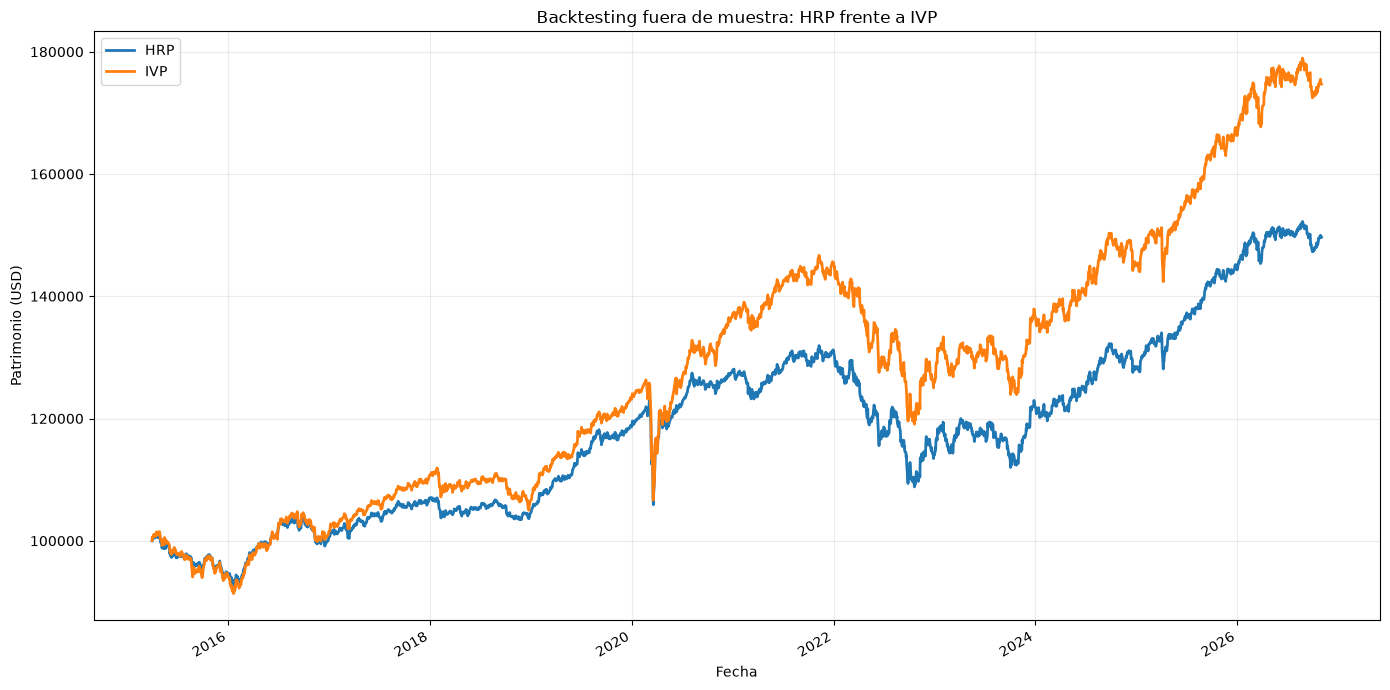

In [30]:
nav_hrp_ivp = pd.DataFrame({
    name: result["simulation"]["nav"]
    for name, result in hrp_ivp_results.items()
})

# Both strategies must use the same evaluation dates
assert not nav_hrp_ivp.isna().any().any()

ax = nav_hrp_ivp.plot(
    figsize=(14, 7),
    linewidth=2,
)

ax.set_title(
    "Backtesting fuera de muestra: HRP frente a IVP"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Patrimonio (USD)")

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

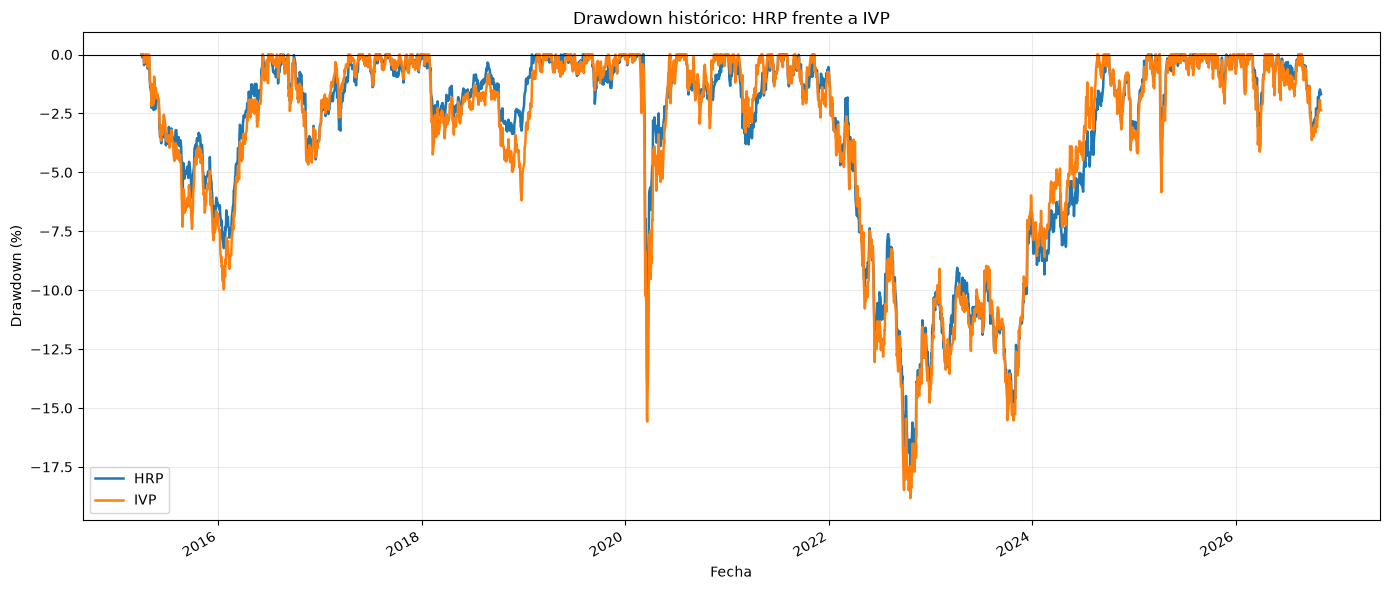

In [31]:
drawdowns_hrp_ivp = (
    nav_hrp_ivp
    / nav_hrp_ivp.cummax()
    - 1.0
)

ax = (
    drawdowns_hrp_ivp * 100
).plot(
    figsize=(14, 6),
    linewidth=1.8,
)

ax.set_title(
    "Drawdown histórico: HRP frente a IVP"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Drawdown (%)")

ax.axhline(
    0,
    color="black",
    linewidth=0.8,
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 7. Backtesting comparativo de estrategias

### 7.1. Objetivo

Se realiza una comparación histórica fuera de muestra de cinco metodologías de construcción de carteras:

1. **Equal Weight:** ponderación idéntica para todos los ETF.
2. **Minimum Variance:** minimización de la varianza de la cartera.
3. **Maximum Sharpe:** maximización del ratio de Sharpe.
4. **Black-Litterman:** combinación de equilibrio y tres opiniones de inversión.
5. **Hierarchical Risk Parity:** asignación mediante clustering y bisección recursiva.

### Metodología experimental

Se utiliza un procedimiento *walk-forward* con las siguientes características:

| Parámetro | Configuración |
|---|---|
| Universo | 12 ETF |
| Moneda | USD |
| Capital inicial | 100.000 USD |
| Frecuencia de datos | Diaria |
| Ventana de entrenamiento | 36 meses |
| Rebalanceo | Trimestral |
| Posiciones cortas | No permitidas |
| Apalancamiento | No permitido |
| Tipo libre de riesgo | 0 % anual |
| Costes iniciales | 0 puntos básicos |

En cada rebalanceo, los modelos utilizan exclusivamente información disponible hasta la fecha de decisión.

Los nuevos pesos se aplican después del cierre de dicha sesión y generan rentabilidad a partir de la siguiente jornada.

Las cinco estrategias comparten los mismos datos y fechas de evaluación.

### Indicadores de evaluación

Se calculan las siguientes métricas:

- CAGR y volatilidad anualizada.
- Sharpe, Sortino y Calmar.
- Maximum Drawdown.
- VaR y Expected Shortfall históricos al 95 %.
- Turnover anualizado.
- Concentración mediante el índice Herfindahl-Hirschman (HHI).
- Número efectivo de activos.
- Patrimonio final.

Las rentabilidades y riesgos se interpretan bajo las hipótesis del experimento, sin extrapolar automáticamente los resultados al futuro.

In [32]:
# Reuse the complete five-strategy baseline experiment.

comparison = bl_comparisons["BL-3"]

STRATEGY_NAMES = [
    "equal_weight",
    "min_variance",
    "max_sharpe",
    "black_litterman",
    "hrp",
]

# Extract the common portfolio NAV series.
portfolio_nav = comparison["nav"].reindex(
    columns=STRATEGY_NAMES
)

portfolio_daily_returns = comparison[
    "portfolio_returns"
].reindex(
    columns=STRATEGY_NAMES
)

# Validate the comparison.
assert not portfolio_nav.empty
assert not portfolio_nav.isna().any().any()
assert not portfolio_daily_returns.isna().any().any()

assert (portfolio_nav > 0).all().all()

print("Primera fecha de evaluación:", portfolio_nav.index.min())
print("Última fecha de evaluación:", portfolio_nav.index.max())

print("\nNúmero de sesiones:", len(portfolio_nav))

print("\nRebalanceos por estrategia:")

for strategy in STRATEGY_NAMES:
    print(
        strategy,
        len(comparison["weights"][strategy]),
    )

Primera fecha de evaluación: 2015-03-31 00:00:00
Última fecha de evaluación: 2026-11-02 00:00:00

Número de sesiones: 2916

Rebalanceos por estrategia:
equal_weight 47
min_variance 47
max_sharpe 47
black_litterman 47
hrp 47


In [33]:
backtest_metrics = evaluate_backtest(
    comparison_result=comparison,
    risk_free_rate=0.0,
    periods_per_year=252,
)

# Capital at the end of the simulation.
backtest_metrics["final_nav"] = (
    portfolio_nav.iloc[-1]
)

# Improve labels for presentation.
STRATEGY_LABELS = {
    "equal_weight": "Equal Weight",
    "min_variance": "Minimum Variance",
    "max_sharpe": "Maximum Sharpe",
    "black_litterman": "Black-Litterman",
    "hrp": "HRP",
}

backtest_metrics.index = backtest_metrics.index.map(
    STRATEGY_LABELS
)

display(backtest_metrics.round(4))

,cagr,volatility,sharpe,sortino,max_drawdown,calmar,var_95,cvar_95,annual_turnover,total_costs,average_hhi,average_effective_assets,final_nav
strategy,,,,,,,,,,,,,
Equal Weight,0.0621,0.0921,0.7009,0.9738,-0.2017,0.3082,0.0084,0.0136,0.2498,0.0000,0.0833,12.0000,200900.3501
Minimum Variance,0.0208,0.0507,0.4322,0.6056,-0.1602,0.1301,0.0049,0.0076,0.5846,0.0000,0.4170,2.5266,126943.7656
Maximum Sharpe,0.0603,0.0959,0.6583,0.9264,-0.1875,0.3214,0.0090,0.0149,1.8404,0.0000,0.4489,2.4296,196830.2446
Black-Litterman,0.0746,0.1027,0.7519,1.0472,-0.1899,0.3927,0.0097,0.0153,1.6109,0.0000,0.2889,3.6142,229830.5443
HRP,0.0355,0.0597,0.6137,0.8632,-0.1752,0.2024,0.0056,0.0088,0.6063,0.0000,0.1888,5.4241,149666.8526


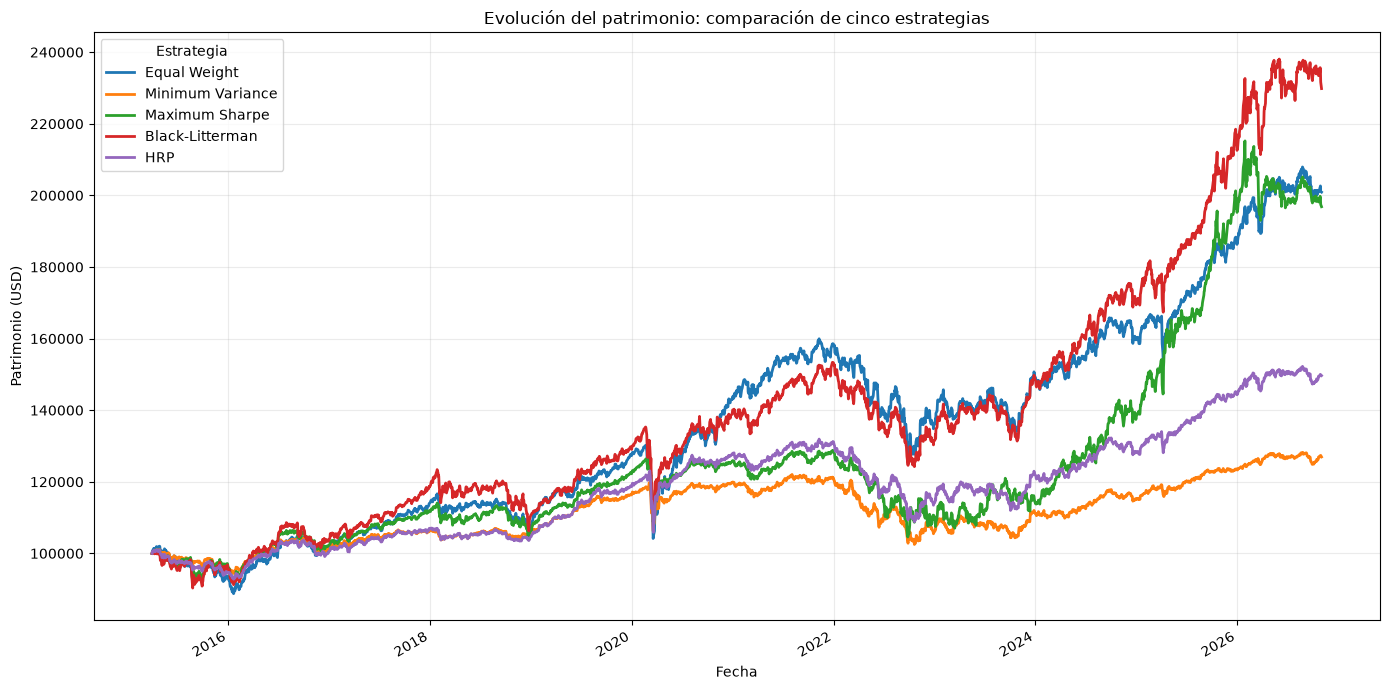

In [34]:
fig, ax = plt.subplots(figsize=(14, 7))

portfolio_nav.rename(
    columns=STRATEGY_LABELS
).plot(
    ax=ax,
    linewidth=2,
)

ax.set_title(
    "Evolución del patrimonio: comparación de cinco estrategias"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Patrimonio (USD)")

ax.grid(alpha=0.25)

ax.legend(
    title="Estrategia",
    loc="upper left",
)

plt.tight_layout()
plt.show()

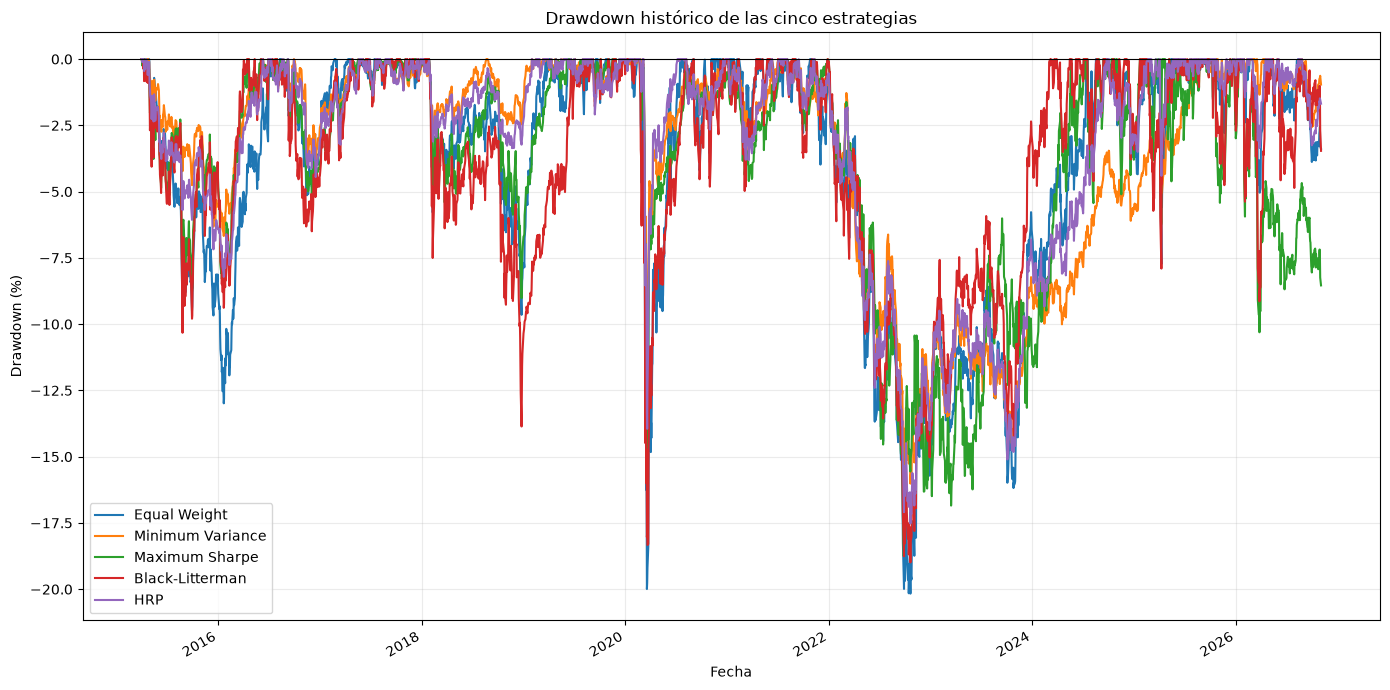

In [35]:
INITIAL_CAPITAL = 100_000.0

# Include the initial capital as the reference high-water mark.
running_peak = portfolio_nav.cummax().clip(
    lower=INITIAL_CAPITAL
)

drawdowns = (
    portfolio_nav / running_peak - 1.0
)

fig, ax = plt.subplots(figsize=(14, 7))

(drawdowns * 100).rename(
    columns=STRATEGY_LABELS
).plot(
    ax=ax,
    linewidth=1.5,
)

ax.set_title(
    "Drawdown histórico de las cinco estrategias"
)

ax.set_xlabel("Fecha")
ax.set_ylabel("Drawdown (%)")

ax.axhline(0, color="black", linewidth=0.8)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### 7.2. Concentración de capital y diversificación

Además de la rentabilidad, resulta importante analizar la distribución de los pesos entre activos.

Se utiliza el índice Herfindahl-Hirschman:

$$
HHI_t = \sum_{i=1}^{N} w_{i,t}^2
$$

El número efectivo de activos se calcula mediante:

$$
N_{\mathrm{eff},t} = \frac{1}{HHI_t}
$$

Una cartera equiponderada entre 12 activos tiene:

$$
HHI = \frac{1}{12}
$$

$$
N_{\mathrm{eff}} = 12
$$

El número efectivo de activos disminuye cuando la asignación se concentra.

Esta métrica describe la distribución del capital, no la diversificación de las fuentes de riesgo.

Por ello, debe interpretarse conjuntamente con las volatilidades, correlaciones y contribuciones individuales al riesgo.

En el análisis utilizamos las ponderaciones objetivo calculadas en cada rebalanceo.

In [36]:
# Average concentration metrics from the validated backtest.

concentration_summary = backtest_metrics[
    [
        "average_hhi",
        "average_effective_assets",
        "annual_turnover",
    ]
].copy()

concentration_summary.columns = [
    "HHI medio",
    "Activos efectivos medios",
    "Turnover anual",
]

display(
    concentration_summary.round(4)
)

,HHI medio,Activos efectivos medios,Turnover anual
strategy,,,
Equal Weight,0.0833,12.0000,0.2498
Minimum Variance,0.4170,2.5266,0.5846
Maximum Sharpe,0.4489,2.4296,1.8404
Black-Litterman,0.2889,3.6142,1.6109
HRP,0.1888,5.4241,0.6063


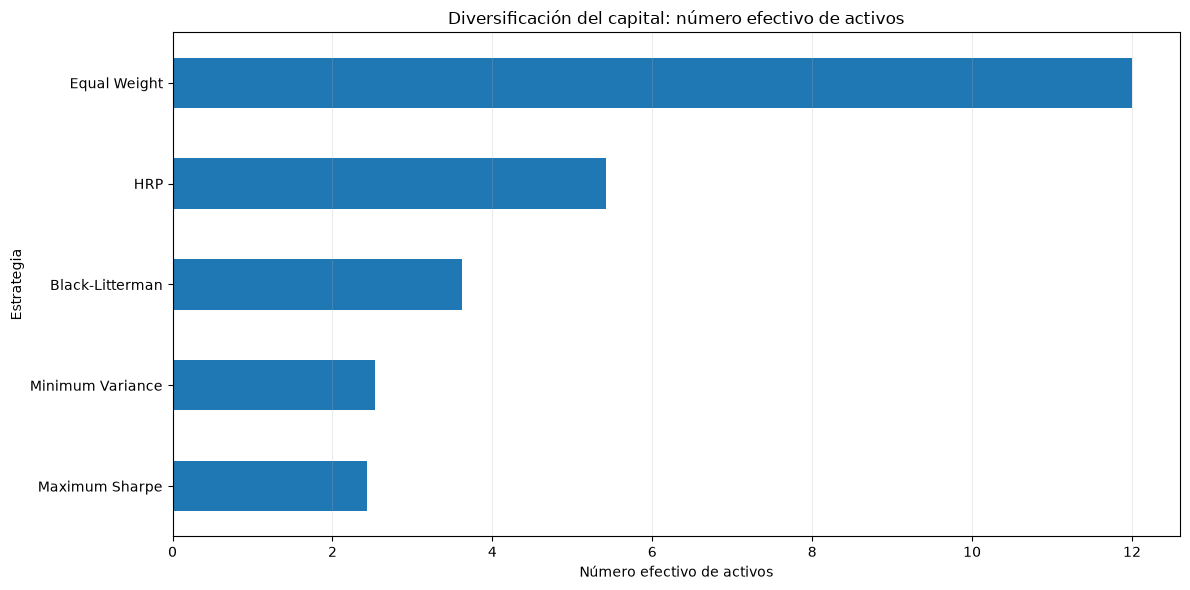

In [37]:
fig, ax = plt.subplots(figsize=(12, 6))

concentration_summary[
    "Activos efectivos medios"
].sort_values().plot(
    kind="barh",
    ax=ax,
)

ax.set_title(
    "Diversificación del capital: número efectivo de activos"
)

ax.set_xlabel("Número efectivo de activos")
ax.set_ylabel("Estrategia")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### 7.3. Interpretación comparativa

Los resultados muestran diferencias relevantes entre las cinco metodologías.

**Black-Litterman**

Obtiene el mayor CAGR y Sharpe del experimento.

La incorporación de tres opiniones mejora los resultados históricos frente a la configuración inicial de una sola opinión.

Sin embargo, la cartera presenta una concentración relevante en determinados activos, especialmente SPY.

Además, las opiniones estratégicas se formularon con conocimiento retrospectivo del histórico, lo que limita la validez de una interpretación predictiva de los resultados.

**Equal Weight**

Presenta una rentabilidad elevada y una distribución uniforme del capital.

Su sencillez reduce la dependencia de estimaciones de rentabilidades esperadas y covarianzas.

**Minimum Variance**

Consigue la menor volatilidad realizada y el menor drawdown.

Sin embargo, presenta una rentabilidad inferior y una concentración importante en determinados ETF de renta fija.

**Maximum Sharpe**

Obtiene una rentabilidad próxima a Equal Weight, pero presenta una elevada concentración y cambios frecuentes en sus asignaciones objetivo.

Esto resulta consistente con la sensibilidad de la optimización media-varianza a los parámetros estimados.

**Hierarchical Risk Parity**

Presenta una volatilidad reducida y asignaciones relativamente estables.

No obstante, su rentabilidad histórica es inferior a la de las estrategias con mayor exposición al riesgo.

### Conclusión provisional

No existe una estrategia que domine a todas las demás en cada dimensión.

La selección depende del mandato de inversión, de las restricciones de riesgo y de la importancia asignada a la estabilidad de las posiciones.

La comparación debe completarse incorporando costes de transacción y pruebas de robustez.

## 8. Robustez y costes de transacción

### 8.1. Sensibilidad a los costes

Una estrategia puede presentar resultados atractivos antes de costes y perder parte de su ventaja cuando se consideran los gastos asociados a las operaciones.

El impacto depende principalmente de:

- La frecuencia de rebalanceo.
- La magnitud de las operaciones.
- La variabilidad de los pesos objetivo.
- Los costes efectivos de ejecución.

En esta práctica se utiliza un modelo de costes proporcionales al importe negociado:

$$
C_t = c \sum_{i=1}^{N} |\Delta H_{i,t}|
$$

Donde:

- $C_t$ representa el coste de transacción.
- $c$ es el coste proporcional.
- $\Delta H_{i,t}$ es la variación monetaria de la posición en el activo $i$.

Se consideran cuatro escenarios:

| Escenario | Coste |
|---|---:|
| Sin costes | 0 bps |
| Costes reducidos | 5 bps |
| Costes moderados | 10 bps |
| Costes elevados | 20 bps |

Un punto básico equivale al 0,01 %.

Los costes se descuentan directamente del patrimonio durante cada rebalanceo.

El modelo utiliza los mismos pesos objetivo para todos los escenarios. Por tanto, permite aislar el impacto de los costes sin modificar las decisiones de inversión.

No incorpora explícitamente horquillas variables, impacto de mercado, fiscalidad, financiación ni diferencias de liquidez entre ETF.

In [38]:
from quantmgmt.backtesting.engine import simulate_portfolio

COST_SCENARIOS = [0, 5, 10, 20]

cost_sensitivity_rows = []
cost_sensitivity_results = {}

for cost_bps in COST_SCENARIOS:

    print(f"Calculando escenario: {cost_bps} bps")

    scenario_results = {}

    for strategy in STRATEGY_NAMES:

        target_weights = comparison["weights"][strategy]

        simulation = simulate_portfolio(
            returns=returns,
            target_weights=target_weights,
            initial_capital=100_000.0,
            transaction_cost_bps=cost_bps,
        )

        scenario_results[strategy] = simulation

    # Build the structure expected by evaluate_backtest()
    scenario_comparison = {
        "weights": comparison["weights"],
        "results": scenario_results,

        "nav": pd.DataFrame({
            strategy: result["nav"]
            for strategy, result in scenario_results.items()
        }),

        "portfolio_returns": pd.DataFrame({
            strategy: result["portfolio_returns"]
            for strategy, result in scenario_results.items()
        }),

        "turnover": pd.DataFrame({
            strategy: result["turnover"]
            for strategy, result in scenario_results.items()
        }),

        "costs": pd.DataFrame({
            strategy: result["costs"]
            for strategy, result in scenario_results.items()
        }),
    }

    scenario_metrics = evaluate_backtest(
        comparison_result=scenario_comparison,
        risk_free_rate=0.0,
        periods_per_year=252,
    )

    for strategy in STRATEGY_NAMES:

        metrics = scenario_metrics.loc[strategy]

        cost_sensitivity_rows.append({
            "Strategy": strategy,
            "Cost (bps)": cost_bps,
            "CAGR": metrics["cagr"],
            "Sharpe": metrics["sharpe"],
            "Final NAV": scenario_results[
                strategy
            ]["nav"].iloc[-1],
            "Total Costs": metrics["total_costs"],
        })

    cost_sensitivity_results[cost_bps] = (
        scenario_comparison
    )

cost_sensitivity = pd.DataFrame(
    cost_sensitivity_rows
)

cagr_by_cost = cost_sensitivity.pivot(
    index="Strategy",
    columns="Cost (bps)",
    values="CAGR",
)

cagr_by_cost = cagr_by_cost.reindex(
    STRATEGY_NAMES
)

print("CAGR (%) según los costes de transacción:")

display(
    (
        cagr_by_cost.rename(
            index=STRATEGY_LABELS
        ) * 100
    ).round(2)
)

Calculando escenario: 0 bps
Calculando escenario: 5 bps
Calculando escenario: 10 bps
Calculando escenario: 20 bps
CAGR (%) según los costes de transacción:


Cost (bps),0,5,10,20
Strategy,,,,
Equal Weight,6.2100,6.2000,6.1900,6.1600
Minimum Variance,2.0800,2.0500,2.0200,1.9600
Maximum Sharpe,6.0300,5.9300,5.8300,5.6400
Black-Litterman,7.4600,7.3700,7.2800,7.1100
HRP,3.5500,3.5100,3.4800,3.4200


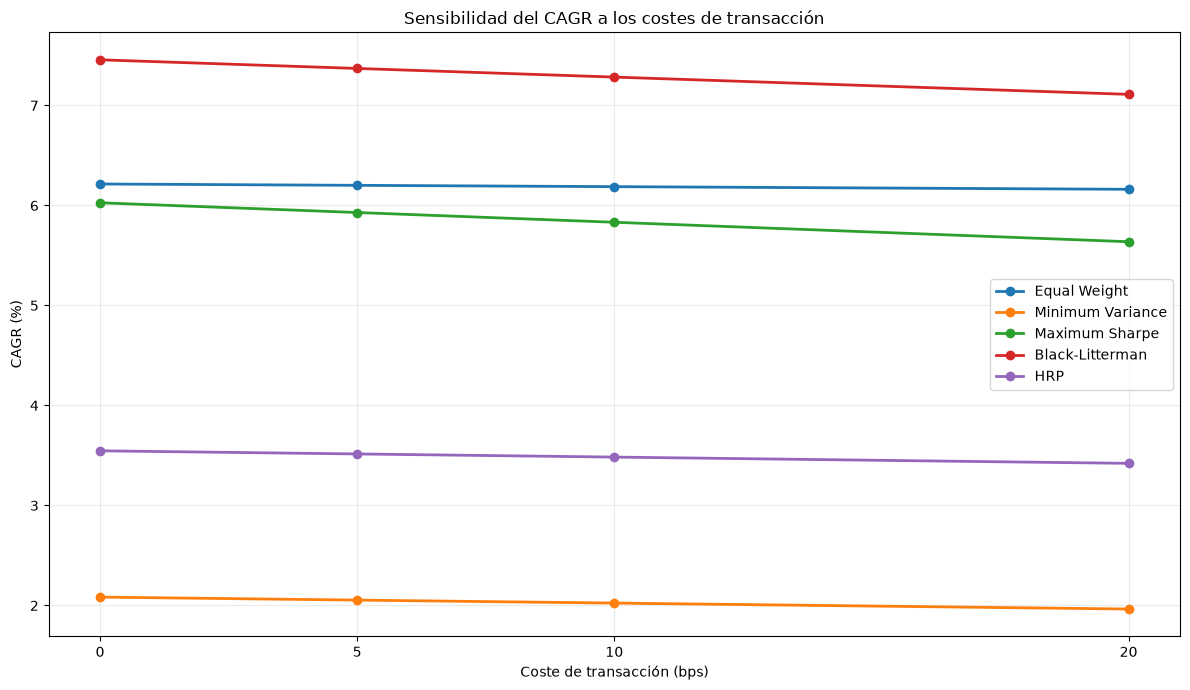

In [39]:
fig, ax = plt.subplots(figsize=(12, 7))

for strategy in STRATEGY_NAMES:

    row = cagr_by_cost.loc[strategy]

    ax.plot(
        row.index,
        row.values * 100,
        marker="o",
        linewidth=2,
        label=STRATEGY_LABELS[strategy],
    )

ax.set_title(
    "Sensibilidad del CAGR a los costes de transacción"
)

ax.set_xlabel("Coste de transacción (bps)")
ax.set_ylabel("CAGR (%)")

ax.set_xticks(COST_SCENARIOS)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

In [40]:
cost_impact = pd.DataFrame({
    "CAGR sin costes": cagr_by_cost[0],
    "CAGR con 20 bps": cagr_by_cost[20],
})

cost_impact["Reduction (pp)"] = (
    cost_impact["CAGR sin costes"]
    - cost_impact["CAGR con 20 bps"]
) * 100

cost_impact = cost_impact.rename(
    index=STRATEGY_LABELS
)

display(cost_impact.round(4))

,CAGR sin costes,CAGR con 20 bps,Reduction (pp)
Strategy,,,
Equal Weight,0.0621,0.0616,0.0530
Minimum Variance,0.0208,0.0196,0.1193
Maximum Sharpe,0.0603,0.0564,0.3896
Black-Litterman,0.0746,0.0711,0.3456
HRP,0.0355,0.0342,0.1255


### 8.2. Turnover y estabilidad de las asignaciones

El turnover mide el importe negociado en relación con el patrimonio.

En nuestro motor de simulación se calcula como:

$$
TO_t =
\frac{\sum_i |\Delta H_{i,t}|}
{NAV_{t^-}}
$$

Donde $NAV_{t^-}$ representa el patrimonio inmediatamente anterior al rebalanceo.

La medida incluye compras y ventas en valor absoluto. Por tanto, una sustitución completa de una cartera por otra puede generar un turnover próximo al 200 %.

Se anualiza utilizando la frecuencia de observaciones del backtesting.

Es importante distinguir entre:

**Turnover realizado**

Considera las operaciones necesarias para alcanzar los pesos objetivo desde las posiciones efectivas del momento.

**Cambio de pesos objetivo**

Mide las diferencias entre asignaciones objetivo consecutivas.

Una estrategia puede mantener los mismos pesos objetivo en todos los trimestres y presentar turnover positivo debido a las variaciones de precios de sus activos.

El turnover de nuestro experimento incluye la inversión inicial, por lo que no debe interpretarse exclusivamente como rotación recurrente de una cartera previamente invertida.

In [41]:
from quantmgmt.backtesting.diagnostics import (
    weight_stability,
)

stability_rows = []

for strategy in STRATEGY_NAMES:

    weights = comparison["weights"][strategy]

    stability = weight_stability(weights)

    stability_rows.append({
        "Strategy": STRATEGY_LABELS[strategy],

        "Annual Turnover": backtest_metrics.loc[
            STRATEGY_LABELS[strategy],
            "annual_turnover",
        ],

        "Average Target Change": (
            stability.iloc[1:].mean()
        ),

        "Maximum Target Change": (
            stability.max()
        ),
    })

stability_comparison = pd.DataFrame(
    stability_rows
).set_index("Strategy")

display(
    (stability_comparison * 100).round(2)
)

,Annual Turnover,Average Target Change,Maximum Target Change
Strategy,,,
Equal Weight,24.9800,0.0000,0.0000
Minimum Variance,58.4600,12.5600,108.0500
Maximum Sharpe,184.0400,45.5100,138.9000
Black-Litterman,161.0900,39.2500,109.6100
HRP,60.6300,12.4800,47.4400


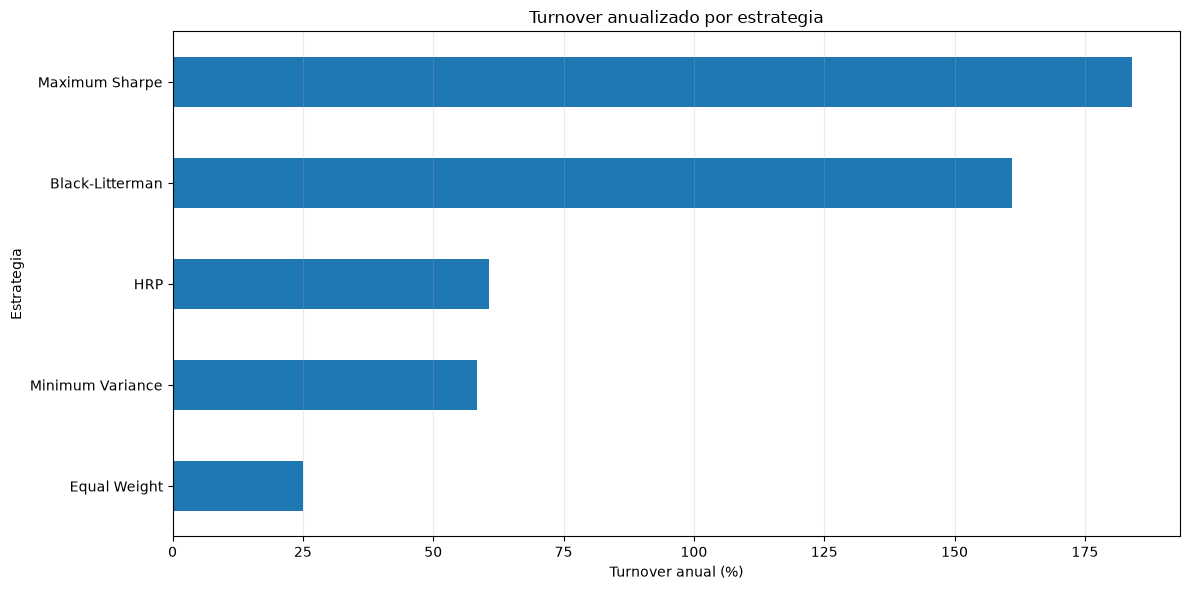

In [42]:
fig, ax = plt.subplots(figsize=(12, 6))

stability_comparison[
    "Annual Turnover"
].mul(100).sort_values().plot(
    kind="barh",
    ax=ax,
)

ax.set_title(
    "Turnover anualizado por estrategia"
)

ax.set_xlabel("Turnover anual (%)")
ax.set_ylabel("Estrategia")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

### 8.3. Validación de la consistencia financiera

Una comparación cuantitativa no debe limitarse a calcular indicadores.

También debe comprobar que las simulaciones respetan las identidades contables y las restricciones de inversión.

Se verifican las siguientes propiedades:

1. Las cinco estrategias comparten las mismas fechas de evaluación.
2. Los patrimonios simulados son positivos.
3. Los pesos objetivo suman uno.
4. No existen posiciones cortas.
5. La capitalización de las rentabilidades reproduce el patrimonio final.
6. Los costes de transacción no incrementan el patrimonio cuando se mantienen constantes las decisiones de inversión.

Estas comprobaciones complementan los tests automatizados del paquete `quantmgmt`.

No eliminan los riesgos derivados de la calidad de datos, la selección del universo o las hipótesis económicas del experimento.

In [43]:
# 1. Common evaluation dates
reference_index = comparison["nav"].index

for strategy in STRATEGY_NAMES:

    result = comparison["results"][strategy]

    assert result["nav"].index.equals(
        reference_index
    )

# 2. Positive portfolio values
assert (
    comparison["nav"] > 0
).all().all()

# 3. Valid portfolio allocations
for strategy in STRATEGY_NAMES:

    weights = comparison["weights"][strategy]

    np.testing.assert_allclose(
        weights.sum(axis=1).to_numpy(),
        np.ones(len(weights)),
        atol=1e-6,
    )

    assert (
        weights >= -1e-8
    ).all().all()

# 4. Accounting consistency
for strategy in STRATEGY_NAMES:

    result = comparison["results"][strategy]

    compounded_return = (
        1.0 + result["portfolio_returns"]
    ).prod()

    final_nav_ratio = (
        result["nav"].iloc[-1] / 100_000.0
    )

    np.testing.assert_allclose(
        compounded_return,
        final_nav_ratio,
        rtol=1e-10,
    )

# 5. Non-negative trading costs
for cost_bps, scenario in cost_sensitivity_results.items():

    assert (
        scenario["costs"] >= -1e-10
    ).all().all()

# 6. Higher costs cannot increase NAV
# when target allocations are unchanged.
for strategy in STRATEGY_NAMES:

    nav_without_costs = (
        cost_sensitivity_results[0]["nav"][strategy]
    )

    for cost_bps in [5, 10, 20]:

        nav_with_costs = (
            cost_sensitivity_results[cost_bps]["nav"][
                strategy
            ]
        )

        np.testing.assert_array_less(
            nav_with_costs.to_numpy()
            - nav_without_costs.to_numpy(),
            np.full(
                len(nav_with_costs),
                1e-6,
            ),
        )

print("Todas las comprobaciones financieras han pasado.")

Todas las comprobaciones financieras han pasado.


### 8.4. Limitaciones metodológicas

Los resultados obtenidos deben interpretarse considerando las limitaciones del experimento.

#### 1. Sesgo retrospectivo en las opiniones

Las opiniones estratégicas de Black-Litterman se han formulado después de conocer el período histórico analizado.

Aunque los parámetros estimados en cada rebalanceo utilizan exclusivamente información anterior a la fecha de decisión, la selección de dichas opiniones puede introducir sesgo retrospectivo.

Por tanto, el buen comportamiento de Black-Litterman no constituye evidencia concluyente de capacidad predictiva futura.

#### 2. Incertidumbre en las estimaciones

Las medias históricas, las covarianzas y las correlaciones son estimaciones sujetas a error.

Maximum Sharpe resulta particularmente sensible a las estimaciones de rentabilidad esperada.

Black-Litterman reduce la dependencia de las medias históricas mediante retornos implícitos, pero introduce incertidumbre relacionada con el benchmark y las opiniones.

HRP evita la inversión directa de la matriz de covarianzas, aunque continúa dependiendo de las correlaciones y varianzas estimadas.

#### 3. Riesgo libre del 0 %

Se utiliza un tipo libre de riesgo anual constante del 0 %.

Esta decisión simplifica la comparación metodológica, pero no representa adecuadamente todos los regímenes monetarios del período estudiado.

Por tanto, los ratios de Sharpe y Sortino deben interpretarse bajo esta hipótesis.

Una evaluación adicional podría incorporar una serie histórica de tipos libres de riesgo.

#### 4. Costes de ejecución

El modelo utiliza costes proporcionales de 0, 5, 10 y 20 puntos básicos.

No incorpora explícitamente impacto de mercado, horquillas variables, fiscalidad, comisiones mínimas ni restricciones de liquidez.

#### 5. Selección de activos

El universo está formado por 12 ETF que proporcionan exposición a distintas clases de activos.

La selección se ha realizado con conocimiento de su existencia y disponibilidad histórica.

Esto puede introducir sesgo de selección y limita la generalización de los resultados a universos más amplios.

#### 6. Horizonte y regímenes de mercado

Los resultados dependen del período de evaluación y de sus condiciones económicas.

Las estrategias pueden comportarse de forma diferente durante períodos prolongados de inflación, crisis crediticias o cambios estructurales en las correlaciones.

#### 7. Concentración del capital

La diversificación del capital no garantiza diversificación de las fuentes de riesgo.

Black-Litterman y Maximum Sharpe han mostrado concentraciones relevantes en determinados activos.

HRP presenta menor volatilidad realizada, pero también concentra parte importante del capital en ETF de renta fija.

### Evaluación de robustez

Se han realizado comprobaciones complementarias:

- Sensibilidad de Black-Litterman a la aversión al riesgo y a la confianza en momentum.
- Comparación de configuraciones con una, dos y tres opiniones.
- Sensibilidad a costes de transacción.
- Análisis de concentración y turnover.
- Comparación de HRP con inversa de volatilidad.
- Comprobaciones contables y restricciones de cartera.

Estas pruebas proporcionan información sobre la estabilidad de los resultados, pero no sustituyen una validación prospectiva independiente.

## 9. Informe al comité de inversión

### 9.1. Resumen ejecutivo

El objetivo de esta práctica ha sido evaluar cinco metodologías de construcción de carteras utilizando un universo diversificado de 12 ETF y un procedimiento de backtesting walk-forward con rebalanceos trimestrales.

El experimento compara enfoques sencillos, como Equal Weight, con metodologías de optimización media-varianza, Black-Litterman y Hierarchical Risk Parity.

Los resultados muestran diferencias importantes tanto en rentabilidad como en volatilidad, concentración y estabilidad de las asignaciones.

### Resultados principales

| Estrategia | CAGR | Volatilidad | Sharpe | Maximum Drawdown |
|---|---:|---:|---:|---:|
| Equal Weight | 6,21 % | 9,21 % | 0,701 | -20,17 % |
| Minimum Variance | 2,08 % | 5,07 % | 0,432 | -16,02 % |
| Maximum Sharpe | 6,03 % | 9,59 % | 0,658 | -18,75 % |
| **Black-Litterman** | **7,46 %** | 10,27 % | **0,752** | -18,99 % |
| HRP | 3,55 % | 5,97 % | 0,614 | -17,52 % |

Black-Litterman presenta la mayor rentabilidad anualizada y el mayor Sharpe del experimento.

Sin embargo, también presenta la mayor volatilidad y una concentración significativa de capital en determinados activos.

Minimum Variance consigue la menor volatilidad y el menor drawdown, pero su rentabilidad es considerablemente inferior.

HRP ofrece una alternativa de menor riesgo y una mayor diversificación del capital que las estrategias optimizadas mediante Markowitz.

Equal Weight obtiene resultados competitivos sin depender de estimaciones de rentabilidades esperadas.

### Evaluación general

Los resultados no permiten identificar una estrategia universalmente superior.

La elección depende del mandato de inversión, de la tolerancia al riesgo y del grado de confianza en las hipótesis utilizadas por cada modelo.

Además, el resultado favorable de Black-Litterman debe interpretarse con cautela debido al posible sesgo retrospectivo en la selección de sus opiniones estratégicas.

### 9.2. Recomendación del comité

Se recomienda utilizar **Equal Weight como cartera de referencia para una eventual implementación inicial**, manteniendo Black-Litterman como candidata para una fase posterior de validación.

Esta recomendación se fundamenta en cuatro consideraciones.

**1. Rentabilidad ajustada al riesgo competitiva**

Equal Weight obtuvo un CAGR del 6,21 % y un Sharpe de 0,701.

Aunque Black-Litterman presenta mejores resultados históricos, la diferencia de Sharpe es relativamente limitada frente a la complejidad adicional de su implementación.

**2. Menor dependencia de estimaciones**

Equal Weight no necesita estimar rentabilidades esperadas, calibrar aversión al riesgo ni definir opiniones subjetivas.

Esto reduce la exposición a errores de estimación y decisiones discrecionales de modelización.

**3. Mayor diversificación del capital**

La estrategia mantiene una asignación objetivo uniforme entre los 12 ETF.

Por el contrario, Black-Litterman presenta un número efectivo medio de aproximadamente 3,61 activos.

No obstante, esta ventaja se refiere exclusivamente a la distribución del capital y no implica una distribución uniforme del riesgo.

**4. Menor rotación operativa**

Equal Weight presenta un turnover anualizado de aproximadamente el 25 %, frente al 161 % de Black-Litterman.

Esta diferencia reduce su sensibilidad a los costes de ejecución y facilita la implementación práctica.

### Papel de Black-Litterman

Black-Litterman se considera una metodología prometedora por su capacidad para combinar una cartera de referencia con hipótesis explícitas de inversión.

En el experimento, la configuración de tres opiniones obtuvo un CAGR del 7,46 % y un Sharpe de 0,752.

Sin embargo, su ventaja histórica depende parcialmente de opiniones seleccionadas con conocimiento retrospectivo.

Antes de recomendar su utilización como cartera principal sería necesario:

- Definir un procedimiento prospectivo y documentado para formular opiniones.
- Validar la estrategia sobre un período temporal no utilizado para desarrollar dichas opiniones.
- Evaluar su comportamiento bajo distintos regímenes de mercado.
- Establecer límites de concentración por activo y clase de activo.
- Incorporar estimaciones realistas de costes y liquidez.

### Papel de HRP

HRP puede resultar apropiada cuando el objetivo prioritario sea limitar la volatilidad y reducir la dependencia de estimaciones de rentabilidad.

En nuestro experimento obtuvo una volatilidad del 5,97 %, frente al 9,21 % de Equal Weight.

Sin embargo, su CAGR fue del 3,55 %.

Además, la comparación con una cartera de inversa de volatilidad mostró que HRP no fue superior en términos de rentabilidad o Sharpe.

### Decisión propuesta

La evidencia disponible respalda la utilización de Equal Weight como referencia sencilla y transparente.

Black-Litterman debería mantenerse en observación hasta disponer de evidencia prospectiva adicional.

Para un mandato específicamente conservador, HRP y Minimum Variance constituirían alternativas que deberían evaluarse según los límites de volatilidad y drawdown establecidos.

### 9.3. Contraargumento de un analista escéptico

Un analista escéptico podría cuestionar tanto el resultado favorable de Black-Litterman como la recomendación de utilizar Equal Weight.

**Primera objeción: la superioridad de Black-Litterman podría ser retrospectiva.**

Las opiniones estratégicas GLD/DBC y SPY/EFA se formularon con conocimiento del histórico analizado.

La mejora de rentabilidad podría deberse parcialmente a la selección de hipótesis que funcionaron en ese período, en lugar de reflejar una capacidad predictiva reproducible.

El procedimiento walk-forward evita que los modelos utilicen observaciones futuras en cada rebalanceo, pero no elimina el sesgo derivado del diseño retrospectivo de las estrategias.

**Segunda objeción: Equal Weight no constituye una cartera neutral al riesgo.**

Asignar el mismo capital a todos los ETF no implica distribuir uniformemente el riesgo.

Los activos de renta variable y los de elevada volatilidad pueden dominar las fluctuaciones de la cartera.

Por tanto, Equal Weight puede ser sencilla y transparente, pero no necesariamente adecuada para un inversor conservador.

**Tercera objeción: el universo de activos condiciona los resultados.**

La selección de ETF, sus exposiciones y el período histórico determinan las oportunidades disponibles para cada metodología.

Un universo diferente podría modificar sustancialmente las conclusiones.

**Cuarta objeción: el horizonte de evaluación es limitado.**

Aunque el backtesting cubre varios regímenes de mercado, continúa representando una única trayectoria histórica.

Los resultados no permiten estimar con precisión el comportamiento futuro de las estrategias ni descartar pérdidas superiores a las observadas.

**Quinta objeción: la comparación no incorpora todos los costes reales.**

Los escenarios de costes proporcionales permiten estudiar la sensibilidad de las estrategias, pero no reproducen necesariamente las condiciones reales de ejecución.

### Respuesta del comité

Estas objeciones son relevantes y deben incorporarse a la decisión de inversión.

La recomendación de Equal Weight no se basa en afirmar que sea matemáticamente óptima.

Se basa en su transparencia, resultados históricos competitivos y menor dependencia de decisiones de calibración.

Black-Litterman mantiene interés como estrategia de investigación, pero su ventaja debe confirmarse mediante una validación verdaderamente prospectiva.

En consecuencia, la decisión del comité debe considerarse provisional y revisable cuando exista nueva evidencia.

## 10. Conclusiones

Esta práctica ha permitido desarrollar, implementar y evaluar dos metodologías avanzadas de construcción de carteras: Black-Litterman y Hierarchical Risk Parity.

Ambos modelos se han comparado con estrategias de referencia mediante un procedimiento walk-forward con ventanas móviles de 36 meses y rebalanceos trimestrales.

### Black-Litterman

El modelo permite combinar rentabilidades implícitas de equilibrio con opiniones explícitas sobre los activos.

La construcción de las matrices \(P\), \(Q\) y \(\Omega\) ha permitido representar tres opiniones relativas y estudiar cómo se propagan sus efectos a través de la matriz de covarianzas.

La configuración de tres opiniones obtuvo el mejor resultado histórico entre las cinco estrategias principales, con un CAGR del 7,46 % y un Sharpe de 0,752.

No obstante, el análisis de atribución mostró que una parte importante de la mejora estaba relacionada con la opinión favorable a SPY frente a EFA.

La selección retrospectiva de las opiniones limita la interpretación predictiva del resultado.

Asimismo, el análisis de sensibilidad mostró que aumentar la confianza en momentum no mejoró necesariamente el comportamiento de la estrategia.

### Hierarchical Risk Parity

HRP utiliza correlaciones, distancias y clustering jerárquico para construir una cartera sin invertir directamente la matriz de covarianzas completa.

La cuasi-diagonalización y la bisección recursiva permiten distribuir el capital considerando la estructura de agrupaciones de los activos.

La estrategia obtuvo una volatilidad anualizada del 5,97 %, inferior a la de Equal Weight y Black-Litterman.

Sin embargo, su rentabilidad fue más reducida.

La comparación con una cartera de inversa de volatilidad mostró que el clustering no garantiza una mejora en términos de rentabilidad o Sharpe.

HRP tampoco garantiza contribuciones individuales iguales al riesgo.

### Comparación de metodologías

Los resultados muestran que las estrategias optimizadas pueden presentar concentraciones importantes y elevada sensibilidad a sus parámetros.

Equal Weight ofrece una referencia competitiva y de implementación sencilla.

Minimum Variance consigue reducir la volatilidad, aunque a costa de una rentabilidad histórica inferior.

Black-Litterman obtuvo el mejor rendimiento del experimento, pero también incorporó una mayor complejidad y dependencia de hipótesis subjetivas.

HRP constituye una alternativa para mandatos orientados al control del riesgo.

### Aprendizajes principales

La construcción cuantitativa de carteras requiere algo más que seleccionar la metodología con mayor rentabilidad histórica.

Es necesario evaluar:

- La calidad de las estimaciones.
- La estabilidad de las asignaciones.
- La concentración del capital y del riesgo.
- El impacto de los costes.
- La validez de las hipótesis económicas.
- La posibilidad de sesgos retrospectivos.
- La consistencia del procedimiento de evaluación.

### Conclusión general

La evidencia obtenida no identifica una metodología universalmente superior.

La selección de una cartera debe partir de un mandato de inversión concreto y de una evaluación rigurosa de los riesgos asociados a cada modelo.

Como decisión provisional, Equal Weight constituye una referencia operativa razonable, mientras que Black-Litterman merece una validación prospectiva adicional antes de considerar su implantación como estrategia principal.

La principal conclusión de la práctica es que **la calidad de una estrategia cuantitativa depende tanto de sus resultados como de la solidez de las hipótesis, las restricciones y el procedimiento utilizado para obtenerlos**.